# Knowledge Graph Completion with R-GCN / CompGCN

**Link prediction on large knowledge graphs** — PySpark ETL + neighbor-sampled R-GCN / CompGCN on a Kaggle T4 (or RTX 4050 / CPU).

| | |
|---|---|
| **Primary dataset** | `ogbl-biokg` (93 773 entities, 51 relations, 4.76 M train triples) |
| **Models** | DistMult · R-GCN · CompGCN (sub / mult / corr) · TransE · ComplEx |
| **Eval** | Filtered 500-candidate ranking **and** official OGB evaluator |
| **Authors** | Charan Ponaganti (240150024) · M Charan (240150018) · Lalit Deshmane (240150044) |

### Notebook map

| § | Section | What it does |
|---|---------|--------------|
| 0 | Setup | Installs (never reinstall torch) |
| 1 | Config | Dataset, machine preset, time budget, flags |
| 2 | Datasets | Why biokg vs Wikidata5M / FB15k-237 |
| 3 | Spark | Session → load → ETL → scalability → tensors |
| 4 | Models | DistMult, R-GCN, CompGCN, TransE, ComplEx |
| 5 | Train / eval | CSR sampling, losses, ranking helpers |
| 6 | Experiments | Fit all models + OGB eval |
| 7 | Ablations | R-GCN half-budget sweeps |
| 8 | Analysis | Curves, errors by degree, UMAP |
| 9 | Export | `results.json`, figures, download zip |

> **Kaggle tip:** set `QUICK_RUN = True` for a ~15–25 min smoke test. For paper numbers use `False` + `TIME_BUDGET = 'fast'`. With `RESUME = True`, finished models are skipped after a restart.


---
## 0 · Environment setup

Install only what is missing. **Do not pip-install torch** — use the Kaggle GPU image.

- `torch-scatter` / `torch-sparse` install **binary wheels only** (compiling them on CUDA 13 kills the kernel).
- `umap-learn` is optional (figures fallback to t-SNE).


In [1]:
# Installs. Never pip-install torch.
# Kaggle Py3.13 + CUDA 13 often has no PyG binary wheels for torch-scatter/sparse;
# compiling them kills the kernel. We skip those; RGCNConv works without them.
import os, sys, subprocess, shutil, platform, importlib
os.environ.setdefault('OUTDATED_IGNORE', '1')

print('python', sys.version)

def pip_install(pkgs, binary_only=False):
    cmd = [sys.executable, '-m', 'pip', 'install', '-q', '--no-cache-dir']
    if binary_only:
        cmd += ['--only-binary=:all:']
    cmd += pkgs
    print(' '.join(cmd))
    subprocess.check_call(cmd)

def ensure(mod, pip_candidates, binary_only=False):
    try:
        importlib.import_module(mod)
        print(mod, 'already present')
        return True
    except Exception:
        pass
    for spec in pip_candidates:
        pkgs = spec if isinstance(spec, list) else [spec]
        try:
            pip_install(pkgs, binary_only=binary_only)
            importlib.invalidate_caches()
            importlib.import_module(mod)
            print('installed', mod, 'via', pkgs)
            return True
        except Exception as e:
            print('skip', pkgs, '->', type(e).__name__, e)
    print('WARNING: could not import', mod)
    return False

ensure('psutil', ['psutil'])
ensure('pyarrow', ['pyarrow'])
ensure('pyspark', ['pyspark==3.5.1', 'pyspark'])
ensure('ogb', ['ogb==1.3.6', 'ogb'])
# umap is optional (figures only) — install lazily later if missing
ensure('torch_geometric', ['torch-geometric==2.6.1', 'torch-geometric'])

import torch
print('torch', torch.__version__, 'cuda', torch.version.cuda,
      'gpu', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

# Optional PyG extensions: binary wheels only. Never compile (that OOMs/kills Kaggle).
if torch.cuda.is_available() and torch.version.cuda:
    tv = torch.__version__.split('+')[0]
    cu = 'cu' + str(torch.version.cuda).replace('.', '')
    url = f'https://data.pyg.org/whl/torch-{tv}+{cu}.html'
    print('PyG wheel index:', url)
    for pkg in ('torch-scatter', 'torch-sparse'):
        try:
            importlib.import_module(pkg.replace('-', '_'))
            print(pkg, 'already present')
        except Exception:
            try:
                pip_install([pkg, '-f', url], binary_only=True)
                print('installed', pkg)
            except Exception as e:
                print(pkg, 'skipped (no binary / not required):', type(e).__name__)

java = shutil.which('java')
print('java:', java, 'JAVA_HOME', os.environ.get('JAVA_HOME'), 'platform:', platform.platform())
if java is None:
    print('WARNING: no java on PATH. Spark needs a JDK.')


python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
psutil already present
pyarrow already present
pyspark already present
/usr/bin/python3 -m pip install -q --no-cache-dir ogb==1.3.6
installed ogb via ['ogb==1.3.6']
/usr/bin/python3 -m pip install -q --no-cache-dir torch-geometric==2.6.1


/usr/local/lib/python3.13/dist-packages/outdated/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


installed torch_geometric via ['torch-geometric==2.6.1']
torch 2.11.0+cu130 cuda 13.0 gpu Tesla T4
PyG wheel index: https://data.pyg.org/whl/torch-2.11.0+cu130.html
/usr/bin/python3 -m pip install -q --no-cache-dir --only-binary=:all: torch-scatter -f https://data.pyg.org/whl/torch-2.11.0+cu130.html
installed torch-scatter
/usr/bin/python3 -m pip install -q --no-cache-dir --only-binary=:all: torch-sparse -f https://data.pyg.org/whl/torch-2.11.0+cu130.html
installed torch-sparse
java: /usr/bin/java JAVA_HOME None platform: Linux-6.18.55+-x86_64-with-glibc2.39


---
## 1 · Configuration

Edit this cell before **Run All**. Everything else reads from these globals.

| Knob | Meaning |
|------|---------|
| `DATASET` | `biokg` (main) · `wikidata5m_subset` · `fb15k237` |
| `QUICK_RUN` | `True` = tiny smoke test; `False` = real tables |
| `TIME_BUDGET` | `fast` ≈ 3–5 h · `long` ≈ 6–9 h (hard stop at `TIME_LIMIT_H`) |
| `MACHINE` | `auto` → `kaggle_t4` / `rtx4050` / `cpu` |
| `MATCHED_DISTMULT` | DistMult uses the **same** epochs/steps/neg as GNNs |
| `ADV_NEG` | RotatE-style self-adversarial negatives |
| `TYPE_AWARE_NEG` | On biokg, corrupt only within the same entity type |
| `EXTRA_DECODERS` | Shallow TransE / ComplEx ablations after the five main models |
| `RESUME` | Reload finished checkpoints from `outputs/` after a restart |


### 1.1 Imports & run knobs

Edit `DATASET`, `QUICK_RUN`, `TIME_BUDGET`, and the upgrade flags here.


In [2]:
import os, time, gc, json, math, random, traceback
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

RUN_START = time.time()

DATASET = 'biokg'          # 'biokg' | 'wikidata5m_subset' | 'fb15k237'
QUICK_RUN = False          # True = smoke test (~15-25 min, all 5 models). False = real tables.
TIME_BUDGET = 'long'       # 'fast' ~3-5h on T4 | 'long' ~6-9h (still under the 11h guard)
MACHINE = 'auto'           # 'auto' | 'kaggle_t4' | 'rtx4050' | 'cpu'
SEED = 42
COMPGCN_OPS = ['sub', 'mult', 'corr']   # every operator runs on every machine; OOM degrades batch/fanout
RUN_ABLATIONS = True       # skipped automatically if the time budget is short
RUN_UMAP = not QUICK_RUN
EVAL_HEAD_AND_TAIL = True
RESUME = True              # reuse finished models from outputs/ after a Kaggle restart
TIME_LIMIT_H = 11.0        # hard stop for new work; Kaggle kills the session at 12h

# --- upgrades (all T4-safe) ---
MATCHED_DISTMULT = True    # DistMult uses the same epochs/steps/neg as the GNNs (fairer comparison)
ADV_NEG = True             # RotatE-style self-adversarial negative weighting
ADV_TEMP = 1.0
TYPE_AWARE_NEG = True      # on ogbl-biokg, corrupt only within the same entity type
EXTRA_DECODERS = ['transe', 'complex']  # shallow decoder ablations after the 5 main models (if time)
KEEP_MODELS_IN_RAM = False  # reload from *.pt for OGB/UMAP — avoids multi-GB host RAM growth
VAL_CANDIDATES = 100         # lighter per-epoch validation (full N_CANDIDATES still used at test)

def elapsed_h():
    return (time.time() - RUN_START) / 3600

def time_left_h():
    return TIME_LIMIT_H - elapsed_h()



### 1.2 Paths & machine detection


In [3]:
IS_KAGGLE = os.path.exists('/kaggle/working') or os.path.exists('/kaggle/input')
if IS_KAGGLE:
    ROOT = Path('/kaggle/working')
    KAGGLE_INPUT = Path('/kaggle/input')
    OUT, FIG = ROOT / 'outputs', ROOT / 'figures'
    SPARK_TMP = str(ROOT / 'spark-tmp')
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    KAGGLE_INPUT = ROOT / 'data'
    OUT, FIG = ROOT / 'outputs', ROOT / 'report' / 'figures'
    SPARK_TMP = str(ROOT / 'spark-tmp')
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
Path(SPARK_TMP).mkdir(parents=True, exist_ok=True)

def detect_machine():
    if not torch.cuda.is_available():
        return 'cpu'
    name = torch.cuda.get_device_name(0).lower()
    mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f'Detected GPU: {torch.cuda.get_device_name(0)}  VRAM={mem_gb:.1f} GB')
    if '4050' in name or mem_gb < 8.5:
        return 'rtx4050'
    if 't4' in name or mem_gb >= 14:
        return 'kaggle_t4'
    return 'rtx4050' if mem_gb < 12 else 'kaggle_t4'

if MACHINE == 'auto':
    MACHINE = detect_machine()
print('MACHINE', MACHINE, '| DATASET', DATASET, '| QUICK_RUN', QUICK_RUN, '| IS_KAGGLE', IS_KAGGLE)



Detected GPU: Tesla T4  VRAM=14.6 GB
MACHINE kaggle_t4 | DATASET biokg | QUICK_RUN False | IS_KAGGLE True


### 1.3 Presets & training budget

`MATCHED_DISTMULT` forces DistMult onto the GNN step/epoch/neg budget.


In [4]:
PRESETS = {
    'kaggle_t4': dict(BATCH_SIZE=512, FANOUT=[10, 10], EMBED_DIM=128, NUM_NEG=16,
                      SPARK_DRIVER_MEMORY='12g', SHUFFLE_PARTITIONS=8, NUM_LAYERS=2, NUM_BASES=8),
    'rtx4050':   dict(BATCH_SIZE=256,  FANOUT=[8, 8],   EMBED_DIM=64, NUM_NEG=8,
                      SPARK_DRIVER_MEMORY='8g',  SHUFFLE_PARTITIONS=4, NUM_LAYERS=2, NUM_BASES=4),
    'cpu':       dict(BATCH_SIZE=128,  FANOUT=[5, 5],   EMBED_DIM=32, NUM_NEG=8,
                      SPARK_DRIVER_MEMORY='8g',  SHUFFLE_PARTITIONS=4, NUM_LAYERS=1, NUM_BASES=4),
}
P = PRESETS[MACHINE].copy()
T4 = MACHINE == 'kaggle_t4'
# DistMult is cheap, so it gets more steps than the GNNs; the report states this.
if QUICK_RUN:
    P.update(dict(BATCH_SIZE=min(P['BATCH_SIZE'], 128), FANOUT=[5], EMBED_DIM=32, NUM_NEG=4,
                  NUM_LAYERS=1, NUM_BASES=4, VAL_TRIPLES=300))
    EPOCHS_DM = EPOCHS_GNN = 1
    STEPS_DM = STEPS_GNN = 30
    NUM_NEG_DM = 4
    MAX_TRAIN_TRIPLES = 8000
    MAX_EVAL_TRIPLES = 500
    RUN_ABLATIONS = False
elif TIME_BUDGET == 'long':
    P.update(dict(VAL_TRIPLES=2000))
    EPOCHS_DM, STEPS_DM, NUM_NEG_DM = (30, 2000, 64) if T4 else (16, 800, 16)
    EPOCHS_GNN, STEPS_GNN = (12, 600) if T4 else (6, 240)
    MAX_TRAIN_TRIPLES = None
    MAX_EVAL_TRIPLES = 15000 if T4 else 6000
else:
    P.update(dict(VAL_TRIPLES=800))
    EPOCHS_DM, STEPS_DM, NUM_NEG_DM = (20, 1500, 32) if T4 else (10, 600, 8)
    EPOCHS_GNN, STEPS_GNN = (8, 400) if T4 else (4, 160)
    MAX_TRAIN_TRIPLES = None
    MAX_EVAL_TRIPLES = 8000 if T4 else 3000

EPOCHS = EPOCHS_GNN
P['STEPS_PER_EPOCH'] = STEPS_GNN
LR = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
DROPOUT = 0.2
PATIENCE = 5
NUM_NEG = P['NUM_NEG']
if MATCHED_DISTMULT and not QUICK_RUN:
    EPOCHS_DM, STEPS_DM, NUM_NEG_DM = EPOCHS_GNN, STEPS_GNN, NUM_NEG
    print('MATCHED_DISTMULT: DistMult uses same budget as GNNs')
BATCH_SIZE = P['BATCH_SIZE']
FANOUT = P['FANOUT']
EMBED_DIM = P['EMBED_DIM']
NUM_LAYERS = P['NUM_LAYERS']
NUM_BASES = P['NUM_BASES']
STEPS_PER_EPOCH = STEPS_GNN
VAL_TRIPLES_PER_EPOCH = P['VAL_TRIPLES']
MIN_DEGREE = 5
TOP_K_ENTITIES = 40000 if MACHINE == 'rtx4050' else 80000
K_CORE = 2
ADD_INVERSE = True
N_CANDIDATES = 200 if MACHINE == 'rtx4050' else 500
LABEL_SMOOTH = 0.1
MIN_H_PER_MODEL = 0.05 if QUICK_RUN else 0.4   # do not start a model with less time than this



MATCHED_DISTMULT: DistMult uses same budget as GNNs


### 1.4 Device, seed, memory helper


In [5]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True

set_seed()

def mem_report(tag=''):
    ram = ''
    try:
        import psutil
        v = psutil.virtual_memory()
        ram = f' | ram={v.used/1e9:.1f}/{v.total/1e9:.1f}GB'
    except Exception:
        pass
    gpu = ''
    if torch.cuda.is_available():
        gpu = f' | cuda={torch.cuda.memory_allocated()/1e9:.2f}GB peak={torch.cuda.max_memory_allocated()/1e9:.2f}GB'
    print(f'[mem {tag}] t={elapsed_h():.2f}h{ram}{gpu}')

n_models = 1 + 1 + len(COMPGCN_OPS)
print('preset', P)
print('DEVICE', DEVICE, 'AMP', USE_AMP, 'dim', EMBED_DIM)
print('DistMult', EPOCHS_DM, 'ep x', STEPS_DM, 'steps, neg', NUM_NEG_DM)
print('GNN     ', EPOCHS_GNN, 'ep x', STEPS_GNN, 'steps, neg', NUM_NEG, '| ops', COMPGCN_OPS)
print('models', n_models, '| TIME_BUDGET', 'quick' if QUICK_RUN else TIME_BUDGET, '| limit', TIME_LIMIT_H, 'h')
mem_report('start')


preset {'BATCH_SIZE': 512, 'FANOUT': [10, 10], 'EMBED_DIM': 128, 'NUM_NEG': 16, 'SPARK_DRIVER_MEMORY': '12g', 'SHUFFLE_PARTITIONS': 8, 'NUM_LAYERS': 2, 'NUM_BASES': 8, 'VAL_TRIPLES': 2000, 'STEPS_PER_EPOCH': 600}
DEVICE cuda AMP True dim 128
DistMult 12 ep x 600 steps, neg 16
GNN      12 ep x 600 steps, neg 16 | ops ['sub', 'mult', 'corr']
models 5 | TIME_BUDGET long | limit 11.0 h
[mem start] t=0.00h | ram=1.7/33.7GB | cuda=0.00GB peak=0.00GB


---
## 2 · Dataset choice

Full-batch R-GCN / CompGCN on Wikidata5M or `ogbl-wikikg2` does **not** fit a 16 GB T4.
`ogbl-biokg` is the largest OGB KG whose entity table and sampled neighborhoods fit.
Wikidata5M remains available as a Spark degree / k-core **subset** option; FB15k-237 is for smoke tests.


In [6]:
CANDIDATES = [
    dict(name='ogbl-biokg', entities=93773, relations=51, triples=4762678, mem='~0.2 GB raw', t4_full='no/tight', t4_mini='yes', avail='OGB / Kaggle'),
    dict(name='ogbl-wikikg2', entities=2500604, relations=535, triples=16109182, mem='~1-2 GB', t4_full='no', t4_mini='very hard', avail='OGB'),
    dict(name='Wikidata5M', entities=4594485, relations=822, triples=20614279, mem='~1-2 GB text', t4_full='no', t4_mini='no (use subset)', avail='KEPLER / Kaggle'),
    dict(name='FB15k-237', entities=14541, relations=237, triples=272115, mem='<20 MB', t4_full='yes', t4_mini='yes', avail='mirrors'),
    dict(name='WN18RR', entities=40943, relations=11, triples=86835, mem='<10 MB', t4_full='yes', t4_mini='yes', avail='mirrors'),
]
print(pd.DataFrame(CANDIDATES).to_string(index=False))
print('\nSelected DATASET =', DATASET)

        name  entities  relations  triples          mem  t4_full         t4_mini           avail
  ogbl-biokg     93773         51  4762678  ~0.2 GB raw no/tight             yes    OGB / Kaggle
ogbl-wikikg2   2500604        535 16109182      ~1-2 GB       no       very hard             OGB
  Wikidata5M   4594485        822 20614279 ~1-2 GB text       no no (use subset) KEPLER / Kaggle
   FB15k-237     14541        237   272115       <20 MB      yes             yes         mirrors
      WN18RR     40943         11    86835       <10 MB      yes             yes         mirrors

Selected DATASET = biokg


---
## 3 · PySpark pipeline

Spark does the heavy relational work; the GPU only sees dense int64 tensors.

### 3.1 Spark session

`local[*]`, Arrow on, Kryo serializer. Driver memory comes from the machine preset.
**The session is stopped before GPU training** so the JVM does not steal host RAM.


In [7]:
from pyspark.sql import SparkSession, Window, functions as SF
from pyspark.sql.types import StructType, StructField, StringType, LongType

def build_spark():
    spark = (
        SparkSession.builder.master('local[*]')
        .appName('kg-completion')
        .config('spark.driver.memory', P['SPARK_DRIVER_MEMORY'])
        .config('spark.driver.maxResultSize', '4g')
        .config('spark.sql.shuffle.partitions', str(P['SHUFFLE_PARTITIONS']))
        .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
        .config('spark.sql.execution.arrow.pyspark.fallback.enabled', 'true')
        .config('spark.local.dir', SPARK_TMP)
        .config('spark.ui.showConsoleProgress', 'true')
        .config('spark.serializer', 'org.apache.spark.serializer.KryoSerializer')
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel('WARN')
    return spark

spark = build_spark()
print(spark.version, spark.sparkContext.master, 'defaultParallelism', spark.sparkContext.defaultParallelism)

TRIPLE_SCHEMA = StructType([
    StructField('h', StringType(), False),
    StructField('r', StringType(), False),
    StructField('t', StringType(), False),
])

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/06 10:55:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/06 10:55:43 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


4.0.4 local[*] defaultParallelism 4


### 3.2 Load triples

Search order: `/kaggle/input` → OGB downloader → local `data/` → GitHub FB15k-237.
On biokg, entity IDs are the official type-aware global integers (no string hash collisions).


#### Load helpers (FB15k-237 / Wikidata5M / synthetic)


In [8]:
def find_dir_with(*names):
    """Shallow search only — rglob on all of /kaggle/input can take minutes."""
    root = KAGGLE_INPUT
    if not root.exists():
        return None
    candidates = [root, *([p for p in root.iterdir() if p.is_dir()] if root.is_dir() else [])]
    for p in candidates:
        if all((p / n).exists() for n in names):
            return p
        for child in list(p.iterdir())[:50] if p.is_dir() else []:
            if child.is_dir() and all((child / n).exists() for n in names):
                return child
    return None

def read_triple_file(path):
    rows = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 3:
                rows.append((parts[0], parts[1], parts[2]))
    return rows

def synthetic_kg(n_ent=500, n_rel=10, n_train=4000, n_valid=400, n_test=400):
    print('WARNING: synthetic KG — pipeline debug only, not for the report.')
    rng = np.random.default_rng(SEED)
    def samp(n):
        h = rng.integers(0, n_ent, size=n)
        r = rng.integers(0, n_rel, size=n)
        t = (h + r + rng.integers(1, 6, size=n)) % n_ent
        return list(zip(h.astype(str), r.astype(str), t.astype(str)))
    return {'train': samp(n_train), 'valid': samp(n_valid), 'test': samp(n_test), 'source': 'synthetic'}

def load_fb15k237():
    d = find_dir_with('train.txt', 'valid.txt', 'test.txt')
    if d is not None and (d / 'train.txt').exists():
        return {s: read_triple_file(d / f'{s}.txt') for s in ['train', 'valid', 'test']} | {'source': str(d)}
    try:
        import urllib.request
        base = 'https://raw.githubusercontent.com/ZhenfengLei/KGDatasets/master/FB15k-237'
        dest = OUT / 'fb15k237'; dest.mkdir(exist_ok=True)
        splits = {}
        for s in ['train', 'valid', 'test']:
            fp = dest / f'{s}.txt'
            if not fp.exists():
                urllib.request.urlretrieve(f'{base}/{s}.txt', fp)
            splits[s] = read_triple_file(fp)
        splits['source'] = str(dest)
        return splits
    except Exception as e:
        print('FB15k-237 download failed:', e)
        return synthetic_kg()

def load_wikidata5m():
    d = find_dir_with('wikidata5m_transductive_train.txt') or find_dir_with('train.txt')
    aliases = {
        'train': ['wikidata5m_transductive_train.txt', 'train.txt'],
        'valid': ['wikidata5m_transductive_valid.txt', 'valid.txt'],
        'test': ['wikidata5m_transductive_test.txt', 'test.txt'],
    }
    if d is None:
        print('Wikidata5M not found under', KAGGLE_INPUT)
        return synthetic_kg(n_ent=2000, n_rel=20, n_train=8000, n_valid=500, n_test=500)
    out = {'source': str(d)}
    for split, names in aliases.items():
        path = next((d / n for n in names if (d / n).exists()), None)
        out[split] = read_triple_file(path)
    return out



#### `ogbl-biokg` loader (type-aware global IDs)


In [9]:
def patch_torch_load_for_ogb():
    import torch as _torch
    if getattr(_torch.load, '_kgc_patched', False):
        return
    _orig = _torch.load
    def _load(*args, **kwargs):
        kwargs.setdefault('weights_only', False)
        return _orig(*args, **kwargs)
    _load._kgc_patched = True
    _torch.load = _load

def _num_nodes_hint(graph):
    if graph is None:
        return None
    if isinstance(graph, dict):
        if 'num_nodes' in graph:
            return int(graph['num_nodes'])
        if 'num_nodes_dict' in graph:
            return int(sum(graph['num_nodes_dict'].values()))
        return None
    n = getattr(graph, 'num_nodes', None)
    nd = getattr(graph, 'num_nodes_dict', None)
    if n is not None:
        try:
            return int(n)
        except Exception:
            pass
    if nd is not None:
        try:
            return int(sum(nd.values()))
        except Exception:
            pass
    return None

def _type_offsets(graph):
    nd = None
    if isinstance(graph, dict):
        nd = graph.get('num_nodes_dict')
    else:
        nd = getattr(graph, 'num_nodes_dict', None)
    if not nd:
        return None, None
    off, start = {}, 0
    for k, n in dict(nd).items():
        off[str(k)] = int(start)
        start += int(n)
    print('biokg type offsets', off, 'n_ent', start)
    return off, int(start)

def _shift_ids(ids, types, offsets):
    ids = np.asarray(ids, dtype=np.int64)
    if offsets is None or types is None:
        return ids
    keys = list(offsets.keys())
    types = np.asarray(types).reshape(-1)
    table = np.empty(len(types), dtype=np.int64)
    for i, t in enumerate(types):
        ts = str(t)
        if ts in offsets:
            table[i] = offsets[ts]
        else:
            try:
                table[i] = offsets[keys[int(t)]]
            except Exception:
                table[i] = 0
    if ids.ndim == 1:
        return ids + table
    return ids + table[:, None]

def load_biokg():
    patch_torch_load_for_ogb()
    ogb_roots = [OUT / 'ogb']
    if KAGGLE_INPUT.exists():
        for p in KAGGLE_INPUT.iterdir():
            if not p.is_dir():
                continue
            if 'biokg' in p.name.lower() or (p / 'ogbl_biokg').exists():
                ogb_roots.insert(0, p)
    last_err = None
    from ogb.linkproppred import LinkPropPredDataset
    for root in ogb_roots:
        try:
            ds = LinkPropPredDataset(name='ogbl-biokg', root=str(root))
            split = ds.get_edge_split()
            graph = ds[0]
            offsets, n_ent_global = _type_offsets(graph)

            def pack(part):
                h = _shift_ids(part['head'], part.get('head_type'), offsets)
                t = _shift_ids(part['tail'], part.get('tail_type'), offsets)
                r = np.asarray(part['relation'])
                rows = list(zip(h.astype(str), r.astype(str), t.astype(str)))
                neg = {}
                if 'head_neg' in part:
                    neg['head_neg'] = _shift_ids(part['head_neg'], part.get('head_type'), offsets)
                    neg['tail_neg'] = _shift_ids(part['tail_neg'], part.get('tail_type'), offsets)
                return rows, neg

            train, _ = pack(split['train'])
            valid, vneg = pack(split['valid'])
            test, tneg = pack(split['test'])
            n_ent_hint = n_ent_global or _num_nodes_hint(graph)
            print('ogbl-biokg loaded', len(train), 'train triples; n_ent_hint', n_ent_hint)
            # Dense type id per global entity for type-aware negative sampling.
            ent_type = None
            if offsets and n_ent_global:
                ent_type = np.full(int(n_ent_global), -1, dtype=np.int64)
                items = list(offsets.items())
                for ti, (_, start) in enumerate(items):
                    end = items[ti + 1][1] if ti + 1 < len(items) else int(n_ent_global)
                    ent_type[int(start):int(end)] = ti
                print('entity types', {k: int((ent_type == i).sum()) for i, k in enumerate(offsets)})
            return {
                'train': train, 'valid': valid, 'test': test,
                'valid_neg': vneg, 'test_neg': tneg,
                'source': f'ogbl-biokg:{root}', 'n_ent_hint': n_ent_hint,
                'type_offsets': offsets, 'ent_type': ent_type,
            }
        except Exception as e:
            last_err = e
            print('ogbl-biokg attempt failed at', root, '->', type(e).__name__, e)
            continue
    print('ogbl-biokg load failed:', last_err)
    raise RuntimeError(f'ogbl-biokg failed to load: {last_err}')



#### Select loader & optional QUICK_RUN truncate


In [10]:
LOADERS = {'biokg': load_biokg, 'fb15k237': load_fb15k237, 'wikidata5m_subset': load_wikidata5m}
raw = LOADERS[DATASET]()
print('source', raw['source'])
print({k: len(raw[k]) for k in ['train', 'valid', 'test']})
if DATASET == 'biokg' and (str(raw.get('source', '')).startswith('synthetic') or len(raw['train']) < 100_000):
    raise RuntimeError(
        f"Not ogbl-biokg. source={raw.get('source')} n_train={len(raw['train'])}. Do not train."
    )
if QUICK_RUN:
    for k in ['train', 'valid', 'test']:
        cap = MAX_TRAIN_TRIPLES if k == 'train' else MAX_EVAL_TRIPLES
        raw[k] = raw[k][:cap]
    print('truncated for QUICK_RUN', {k: len(raw[k]) for k in ['train', 'valid', 'test']})


Downloaded 0.90 GB: 100%|██████████| 920/920 [02:20<00:00,  6.55it/s]


Extracting /kaggle/working/outputs/ogb/biokg.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 3184.74it/s]

Saving...


biokg type offsets {'disease': 0, 'drug': 10687, 'function': 21220, 'protein': 66305, 'sideeffect': 83804} n_ent 93773
ogbl-biokg loaded 4762678 train triples; n_ent_hint 93773
entity types {'disease': 10687, 'drug': 10533, 'function': 45085, 'protein': 17499, 'sideeffect': 9969}
source ogbl-biokg:/kaggle/working/outputs/ogb
{'train': 4762678, 'valid': 162886, 'test': 162870}


### 3.3 ETL helpers

`spark.createDataFrame` ingest → drop nulls / duplicates / self-loops → degree & relation-category stats.


#### Ingest & clean


In [11]:
def rows_to_sdf(rows, name):
    pdf = pd.DataFrame(rows, columns=['h', 'r', 't'])
    # Spark ignores filenames starting with '_', so do not write _ingest_*.parquet.
    try:
        return spark.createDataFrame(pdf, schema=TRIPLE_SCHEMA)
    except Exception as e:
        print('createDataFrame failed, using CSV:', e)
        path = str(OUT / f'ingest_{name}.csv')
        pdf.to_csv(path, index=False, header=False, sep='\t')
        return spark.read.option('delimiter', '\t').schema(TRIPLE_SCHEMA).csv(path)

t0 = time.time()
train_sdf = rows_to_sdf(raw['train'], 'train')
valid_sdf = rows_to_sdf(raw['valid'], 'valid')
test_sdf = rows_to_sdf(raw['test'], 'test')
print('spark ingest s', round(time.time() - t0, 2))

def clean_triples(df, drop_self_loops=True):
    out = df.dropna().dropDuplicates(['h', 'r', 't'])
    out = out.filter((SF.length('h') > 0) & (SF.length('r') > 0) & (SF.length('t') > 0))
    if drop_self_loops:
        out = out.filter(SF.col('h') != SF.col('t'))
    return out

n_raw_train = train_sdf.count()
train_sdf = clean_triples(train_sdf).cache()
valid_sdf = clean_triples(valid_sdf)
test_sdf = clean_triples(test_sdf)
print('train triples raw/clean', n_raw_train, train_sdf.count())



spark ingest s 6.53


train triples raw/clean 4762678 4762676


#### Graph statistics & optional subset filter


In [12]:
def entity_degree(df):
    return (df.select(SF.col('h').alias('e')).union(df.select(SF.col('t').alias('e')))
            .groupBy('e').count().withColumnRenamed('count', 'degree'))

def relation_categories(df, thr=1.5):
    tph = df.groupBy('r', 'h').agg(SF.countDistinct('t').alias('nt')).groupBy('r').agg(SF.avg('nt').alias('tph'))
    hpt = df.groupBy('r', 't').agg(SF.countDistinct('h').alias('nh')).groupBy('r').agg(SF.avg('nh').alias('hpt'))
    j = tph.join(hpt, 'r')
    return j.withColumn(
        'category',
        SF.when((SF.col('tph') < thr) & (SF.col('hpt') < thr), '1-1')
         .when((SF.col('tph') >= thr) & (SF.col('hpt') < thr), '1-N')
         .when((SF.col('tph') < thr) & (SF.col('hpt') >= thr), 'N-1')
         .otherwise('N-N')
    )

deg = entity_degree(train_sdf).cache()
relcat = relation_categories(train_sdf).cache()
n_ent = train_sdf.select('h').union(train_sdf.select('t')).distinct().count()
n_rel = train_sdf.select('r').distinct().count()
n_tri = train_sdf.count()
deg_pd = deg.select('degree').toPandas()['degree']
cat_pd = relcat.groupBy('category').count().toPandas()
print('entities', n_ent, 'relations', n_rel, 'triples', n_tri)
print('degree min/median/mean/p99/max',
      int(deg_pd.min()), float(deg_pd.median()), float(deg_pd.mean()),
      float(deg_pd.quantile(0.99)), int(deg_pd.max()))
print(cat_pd.to_string(index=False))

spark_stats = {
    'n_entities': int(n_ent), 'n_relations': int(n_rel), 'n_triples': int(n_tri),
    'degree_min': int(deg_pd.min()), 'degree_median': float(deg_pd.median()),
    'degree_mean': float(deg_pd.mean()), 'degree_p99': float(deg_pd.quantile(0.99)),
    'degree_max': int(deg_pd.max()),
    'rel_categories': {str(r['category']): int(r['count']) for _, r in cat_pd.iterrows()},
    'duplicates_or_loops_removed': int(n_raw_train - n_tri),
}


entities 93773 relations 51 triples 4762676
degree min/median/mean/p99/max 1 22.0 101.57883399272711 1279.2799999999988 62733
category  count
     N-N     51


### 3.4 Indexing, inverses, filter keys

Dense 0-based ids (or preserve OGB ints), materialize inverse edges for message passing,
build Spark-derived int64 keys of every true triple for GPU filtered ranking, then export NumPy / Torch tensors.


#### Dense ID maps & indexed splits


In [13]:
def degree_filter(df, min_degree, top_k):
    d = entity_degree(df).filter(SF.col('degree') >= min_degree).orderBy(SF.desc('degree')).limit(int(top_k))
    keep = d.select(SF.col('e').alias('id'))
    return (df.join(keep.withColumnRenamed('id', 'h'), 'h')
              .join(keep.withColumnRenamed('id', 't'), 't')
              .select('h', 'r', 't'))

def k_core(df, k, max_iters=12):
    cur = df
    for i in range(max_iters):
        d = entity_degree(cur).filter(SF.col('degree') >= k)
        nxt = (cur.join(d.select(SF.col('e').alias('h')), 'h')
                  .join(d.select(SF.col('e').alias('t')), 't')
                  .select('h', 'r', 't'))
        n0, n1 = cur.count(), nxt.count()
        print(f' k-core iter {i}: {n0} -> {n1}')
        if n1 == n0:
            return nxt
        cur = nxt
    return cur

subset_stats = {}
if DATASET == 'wikidata5m_subset':
    print('Extracting degree/k-core subgraph so GPU training can run...')
    before = {'entities': n_ent, 'triples': n_tri}
    train_sdf = degree_filter(train_sdf, MIN_DEGREE, TOP_K_ENTITIES)
    train_sdf = k_core(train_sdf, K_CORE).cache()
    keep_e = train_sdf.select(SF.col('h').alias('e')).union(train_sdf.select(SF.col('t').alias('e'))).distinct()
    keep_r = train_sdf.select('r').distinct()
    valid_sdf = valid_sdf.join(keep_e.withColumnRenamed('e', 'h'), 'h').join(keep_e.withColumnRenamed('e', 't'), 't').join(keep_r, 'r').select('h', 'r', 't')
    test_sdf = test_sdf.join(keep_e.withColumnRenamed('e', 'h'), 'h').join(keep_e.withColumnRenamed('e', 't'), 't').join(keep_r, 'r').select('h', 'r', 't')
    n_ent = keep_e.count(); n_rel = keep_r.count(); n_tri = train_sdf.count()
    subset_stats = {'before': before, 'after': {'entities': n_ent, 'relations': n_rel, 'triples': n_tri}}
    print('subset', subset_stats)

ents = train_sdf.select(SF.col('h').alias('name')).union(train_sdf.select(SF.col('t').alias('name'))).distinct()
rels = train_sdf.select(SF.col('r').alias('name')).distinct()
# Integer names (OGB) must sort numerically: lexicographic '10' < '2' would scramble official negatives.
ents_cast = ents.withColumn('as_long', SF.col('name').cast(LongType()))
rels_cast = rels.withColumn('as_long', SF.col('name').cast(LongType()))
ids_are_int = ents_cast.filter(SF.col('as_long').isNull()).limit(1).count() == 0
if ids_are_int:
    e_map = ents_cast.select(SF.col('name'), SF.col('as_long').alias('id'))
    r_map = rels_cast.select(SF.col('name'), SF.col('as_long').alias('id'))
    print('preserving integer entity/relation ids (OGB-aligned)')
else:
    e_map = ents.withColumn('id', SF.row_number().over(Window.orderBy('name')) - 1)
    r_map = rels.withColumn('id', SF.row_number().over(Window.orderBy('name')) - 1)

def index_df(df):
    return (df.join(e_map.withColumnRenamed('name', 'h').withColumnRenamed('id', 'h_id'), 'h')
              .join(r_map.withColumnRenamed('name', 'r').withColumnRenamed('id', 'r_id'), 'r')
              .join(e_map.withColumnRenamed('name', 't').withColumnRenamed('id', 't_id'), 't')
              .select(SF.col('h_id').cast('int').alias('h'), SF.col('r_id').cast('int').alias('r'), SF.col('t_id').cast('int').alias('t')))

train_id = index_df(train_sdf).cache()
valid_id = index_df(valid_sdf)
test_id = index_df(test_sdf)
print('indexed train/valid/test', train_id.count(), valid_id.count(), test_id.count())



preserving integer entity/relation ids (OGB-aligned)


26/11/06 10:59:51 WARN TaskSetManager: Stage 104 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.
26/11/06 10:59:55 WARN TaskSetManager: Stage 126 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


indexed train/valid/test 4762676 162886 162870


#### Inverse edges, true-triple tables, Parquet write


In [14]:
n_rel_id = int(r_map.agg(SF.max('id')).collect()[0][0]) + 1
n_ent_id = int(e_map.agg(SF.max('id')).collect()[0][0]) + 1
if ADD_INVERSE:
    inv = train_id.select(SF.col('t').alias('h'), (SF.col('r') + SF.lit(n_rel_id)).alias('r'), SF.col('h').alias('t'))
    train_msg = train_id.unionByName(inv)
    n_rel_msg = 2 * n_rel_id
else:
    train_msg = train_id
    n_rel_msg = n_rel_id
print('message-passing rels', n_rel_msg, 'entities', n_ent_id)

all_true = train_id.unionByName(valid_id).unionByName(test_id)
true_tails = all_true.groupBy('h', 'r').agg(SF.collect_set('t').alias('true_set'))
true_heads = all_true.groupBy('t', 'r').agg(SF.collect_set('h').alias('true_set'))

parquet_dir = OUT / 'parquet'
for name, df in [('train', train_id), ('valid', valid_id), ('test', test_id),
                 ('train_msg', train_msg), ('e_map', e_map), ('r_map', r_map),
                 ('true_tails', true_tails), ('true_heads', true_heads), ('relcat', relcat)]:
    path = str(parquet_dir / name)
    df.coalesce(4).write.mode('overwrite').parquet(path)
    print('wrote', path)

relcat_pd = relcat.select('r', 'category', 'tph', 'hpt').toPandas()
spark_stats.update({'n_entities_indexed': int(n_ent_id), 'n_relations_indexed': int(n_rel_id),
                    'n_rel_msg': int(n_rel_msg), 'subset': subset_stats, 'ids_are_int': bool(ids_are_int)})
print('ETL wall-clock s', round(time.time() - t0, 2))


message-passing rels 102 entities 93773


wrote /kaggle/working/outputs/parquet/train


26/11/06 11:00:06 WARN TaskSetManager: Stage 166 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


wrote /kaggle/working/outputs/parquet/valid


26/11/06 11:00:09 WARN TaskSetManager: Stage 183 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


wrote /kaggle/working/outputs/parquet/test


... (2 outputs left out)

26/11/06 11:00:19 WARN TaskSetManager: Stage 216 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.
26/11/06 11:00:23 WARN TaskSetManager: Stage 221 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


wrote /kaggle/working/outputs/parquet/true_tails


26/11/06 11:00:41 WARN TaskSetManager: Stage 267 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.
26/11/06 11:00:44 WARN TaskSetManager: Stage 270 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


wrote /kaggle/working/outputs/parquet/true_heads
wrote /kaggle/working/outputs/parquet/relcat
ETL wall-clock s 119.55


### 3.5 Spark scalability

Two axes: **data fraction** (10 / 25 / 50 / 100 %) and **shuffle partitions** (2 / 4 / 8 / 16).
The 100 % timing is often a cache hit from the main ETL — reported honestly, not as super-linear scaling.


{'axis': 'fraction', 'x': 0.1, 'approx_triples': 476267, 'seconds': 1.7739250659942627}


{'axis': 'fraction', 'x': 0.25, 'approx_triples': 1190669, 'seconds': 2.2245798110961914}


{'axis': 'fraction', 'x': 0.5, 'approx_triples': 2381338, 'seconds': 2.0500848293304443}
{'axis': 'fraction', 'x': 1.0, 'approx_triples': 4762676, 'seconds': 0.6908872127532959}


{'axis': 'partitions', 'x': 2, 'approx_triples': 4762676, 'seconds': 1.6476449966430664}


{'axis': 'partitions', 'x': 4, 'approx_triples': 4762676, 'seconds': 1.2772817611694336}


{'axis': 'partitions', 'x': 8, 'approx_triples': 4762676, 'seconds': 1.221738576889038}


{'axis': 'partitions', 'x': 16, 'approx_triples': 4762676, 'seconds': 1.279998540878296}


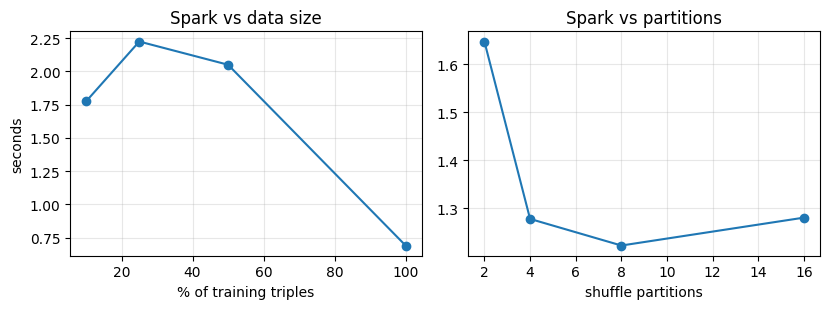

In [15]:
fracs = [0.10, 0.25, 0.50, 1.00] if not QUICK_RUN else [0.25, 1.00]
scale_rows = []
full_n = train_sdf.count()
for fr in fracs:
    part = train_sdf.sample(False, fr, seed=SEED) if fr < 1 else train_sdf
    t1 = time.time()
    _ = part.count()
    _ = entity_degree(part).agg(SF.avg('degree')).collect()
    _ = part.groupBy('r').count().count()
    dt = time.time() - t1
    n = int(full_n * fr) if fr < 1 else full_n
    scale_rows.append({'axis': 'fraction', 'x': fr, 'approx_triples': n, 'seconds': dt})
    print(scale_rows[-1])

part_grid = [2, 4, 8] if QUICK_RUN else [2, 4, 8, 16]
for npart in part_grid:
    t1 = time.time()
    _ = train_sdf.repartition(npart).groupBy('r').count().count()
    dt = time.time() - t1
    scale_rows.append({'axis': 'partitions', 'x': npart, 'approx_triples': full_n, 'seconds': dt})
    print(scale_rows[-1])

scale_df = pd.DataFrame(scale_rows)
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.2))
f = scale_df[scale_df.axis == 'fraction']
ax[0].plot(f['x'] * 100, f['seconds'], marker='o')
ax[0].set_xlabel('% of training triples'); ax[0].set_ylabel('seconds'); ax[0].set_title('Spark vs data size'); ax[0].grid(True, alpha=0.3)
p = scale_df[scale_df.axis == 'partitions']
ax[1].plot(p['x'], p['seconds'], marker='o')
ax[1].set_xlabel('shuffle partitions'); ax[1].set_title('Spark vs partitions'); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / 'fig_spark_scale.png', dpi=160); plt.show()
scale_df.to_csv(OUT / 'spark_scale.csv', index=False)

### 3.6 Degree plot + tensor hand-off

Log-log degree distribution, type-aware negative pools, `TRUE_KEYS` on GPU, official OGB test arrays
(original order), then **`spark.stop()`**.


#### Degree distribution figure


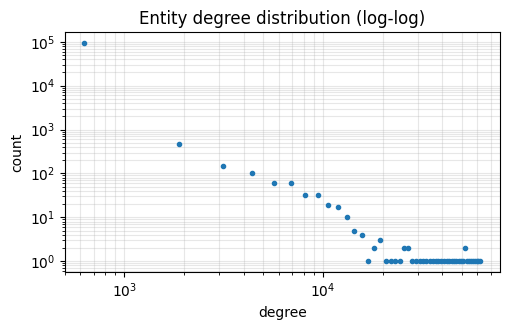

In [16]:
plt.figure(figsize=(5.2, 3.4))
vals, bins = np.histogram(deg_pd, bins=50)
plt.loglog((bins[:-1] + bins[1:]) / 2 + 1e-9, np.maximum(vals, 1), marker='.', linestyle='none')
plt.xlabel('degree'); plt.ylabel('count'); plt.title('Entity degree distribution (log-log)')
plt.grid(True, which='both', alpha=0.3); plt.tight_layout()
plt.savefig(FIG / 'fig_degree_loglog.png', dpi=160); plt.show()



#### Export NumPy tensors & type-aware pools


In [17]:
train_np = train_id.select('h', 'r', 't').toPandas()[['h', 'r', 't']].to_numpy(dtype=np.int64)
valid_np = valid_id.select('h', 'r', 't').toPandas()[['h', 'r', 't']].to_numpy(dtype=np.int64)
test_np = test_id.select('h', 'r', 't').toPandas()[['h', 'r', 't']].to_numpy(dtype=np.int64)
msg_np = train_msg.select('h', 'r', 't').toPandas()[['h', 'r', 't']].to_numpy(dtype=np.int64)
relcat_map = {}
name_to_rid = {str(row['name']): int(row['id']) for row in r_map.select('name', 'id').toPandas().to_dict('records')}
name_to_eid = {str(row['name']): int(row['id']) for row in e_map.select('name', 'id').toPandas().to_dict('records')}
for _, row in relcat_pd.iterrows():
    if str(row['r']) in name_to_rid:
        relcat_map[name_to_rid[str(row['r'])]] = row['category']

N_ENT, N_REL, N_REL_MSG = int(n_ent_id), int(n_rel_id), int(n_rel_msg)

# Type-aware negatives (ogbl-biokg): pool of entity ids per biomedical type.
ENT_TYPE = None
TYPE_POOLS = None
if TYPE_AWARE_NEG and raw.get('ent_type') is not None and ids_are_int:
    et = np.asarray(raw['ent_type'], dtype=np.int64)
    if et.shape[0] >= N_ENT:
        ENT_TYPE = torch.as_tensor(et[:N_ENT], dtype=torch.long)
        TYPE_POOLS = []
        for t in sorted(int(x) for x in ENT_TYPE.unique().tolist() if int(x) >= 0):
            pool = torch.arange(N_ENT)[ENT_TYPE == t]
            TYPE_POOLS.append(pool)
            print(f'  type {t}: {pool.numel()} entities')
        print('TYPE_AWARE_NEG pools', len(TYPE_POOLS))
    else:
        print('ent_type shorter than N_ENT; type-aware off')
elif TYPE_AWARE_NEG:
    print('TYPE_AWARE_NEG requested but no ent_type / non-int ids; using uniform negatives')



26/11/06 11:01:08 WARN TaskSetManager: Stage 477 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.
26/11/06 11:01:13 WARN TaskSetManager: Stage 496 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


  type 0: 10687 entities
  type 1: 10533 entities
  type 2: 45085 entities
  type 3: 17499 entities
  type 4: 9969 entities
TYPE_AWARE_NEG pools 5


#### Filter keys, OGB test arrays, stop Spark


In [18]:
# Filtered ranking: every known (h, r, t) as one int64 key, built by Spark, searched on the GPU.
key_col = ((SF.col('h').cast('long') * SF.lit(N_REL) + SF.col('r').cast('long')) * SF.lit(N_ENT)
           + SF.col('t').cast('long')).alias('k')
true_keys_np = np.unique(all_true.select(key_col).toPandas()['k'].to_numpy(dtype=np.int64))
TRUE_KEYS = torch.as_tensor(true_keys_np, dtype=torch.long).to(DEVICE)
print('filter keys', TRUE_KEYS.numel())

# Official OGB negatives are row-aligned with OGB's test order. Spark dedup/joins reorder rows,
# so the OGB evaluation uses the raw split, never test_np.
OGB_TEST = None
if DATASET == 'biokg' and 'tail_neg' in raw.get('test_neg', {}):
    rows = pd.DataFrame(raw['test'], columns=['h', 'r', 't'])
    if ids_are_int:
        pos = rows.astype(np.int64).to_numpy()
    else:
        pos = np.stack([rows['h'].map(name_to_eid), rows['r'].map(name_to_rid), rows['t'].map(name_to_eid)], 1)
        pos = np.nan_to_num(pos.astype(float), nan=0).astype(np.int64)
    head_neg = np.asarray(raw['test_neg']['head_neg'], dtype=np.int64)
    tail_neg = np.asarray(raw['test_neg']['tail_neg'], dtype=np.int64)
    n = min(len(pos), len(head_neg), len(tail_neg))
    in_range = (pos[:n].max(1) < N_ENT) & (pos[:n, 1] < N_REL) & (head_neg[:n].max(1) < N_ENT) & (tail_neg[:n].max(1) < N_ENT)
    OGB_TEST = {'pos': pos[:n][in_range], 'head_neg': head_neg[:n][in_range], 'tail_neg': tail_neg[:n][in_range]}
    print('OGB test triples (original order)', len(OGB_TEST['pos']), 'dropped out-of-range', int((~in_range).sum()))

print('tensors', train_np.shape, valid_np.shape, test_np.shape, 'N_ENT', N_ENT, 'N_REL', N_REL)

# Drop heavy Python copies now that numpy tensors exist (keeps Kaggle host RAM alive).
for _k in ('train', 'valid', 'test'):
    if _k in raw: raw[_k] = []
if 'ent_type' in raw: raw['ent_type'] = None
gc.collect()

spark.stop(); spark = None; gc.collect()
print('Spark stopped'); mem_report('after-spark')


26/11/06 11:01:19 WARN TaskSetManager: Stage 527 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.
26/11/06 11:01:23 WARN TaskSetManager: Stage 533 contains a task of very large size (2686 KiB). The maximum recommended task size is 1000 KiB.


filter keys 5088432
OGB test triples (original order) 162870 dropped out-of-range 0
tensors (4762676, 3) (162886, 3) (162870, 3) N_ENT 93773 N_REL 51
Spark stopped
[mem after-spark] t=0.10h | ram=10.8/33.7GB | cuda=0.04GB peak=0.04GB


---
## 4 · Model definitions

| Model | Role |
|-------|------|
| **DistMult** | Bilinear decoder $f(h,r,t)=\langle h,r,t\rangle$ — shared by all GNNs; also a shallow baseline |
| **R-GCN** | Relation-specific $W_r$ with basis decomposition ($B$ bases) |
| **CompGCN** | Compose neighbor with relation via $\phi\in\{\mathrm{sub},\mathrm{mult},\mathrm{corr}\}$ |
| **TransE / ComplEx** | Optional shallow decoder ablations (no GNN) |

CompGCN composition (including FFT for `corr`) runs in **float32** with autocast off.
`mult` relations are initialized near ones so $h\odot r$ starts near $h$.


### 4.1 DistMult & R-GCN


In [19]:
def _no_autocast():
    return torch.autocast(device_type=DEVICE.type, enabled=False)

def ccorr(a, b):
    """Circular correlation in float32: half-precision FFTs lose too much precision."""
    n = a.size(-1)
    return torch.fft.irfft(torch.conj(torch.fft.rfft(a, dim=-1)) * torch.fft.rfft(b, dim=-1), n=n, dim=-1)

class DistMultNet(nn.Module):
    def __init__(self, n_ent, n_rel, dim):
        super().__init__()
        self.ent = nn.Embedding(n_ent, dim)
        self.rel = nn.Embedding(n_rel, dim)
        nn.init.xavier_uniform_(self.ent.weight); nn.init.xavier_uniform_(self.rel.weight)
    def score_ids(self, h, r, t):
        return (self.ent(h) * self.rel(r) * self.ent(t)).sum(-1)
    def score_emb(self, he, r, te):
        return (he * self.rel(r) * te).sum(-1)

class RGCNNet(nn.Module):
    def __init__(self, n_ent, n_rel_msg, n_rel, dim, n_layers, n_bases, dropout):
        super().__init__()
        from torch_geometric.nn import RGCNConv
        self.ent = nn.Embedding(n_ent, dim)
        self.rel = nn.Embedding(n_rel, dim)
        self.convs = nn.ModuleList([RGCNConv(dim, dim, num_relations=n_rel_msg, num_bases=n_bases) for _ in range(n_layers)])
        self.dropout = nn.Dropout(dropout)
        nn.init.xavier_uniform_(self.ent.weight); nn.init.xavier_uniform_(self.rel.weight)
    def encode(self, n_id, edge_index, edge_type):
        h = self.ent(n_id)
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index, edge_type)
            if i < len(self.convs) - 1:
                h = self.dropout(F.relu(h))
        return h
    def score_emb(self, he, r, te):
        return (he * self.rel(r) * te).sum(-1)



### 4.2 CompGCN (sub / mult / corr)

Composition runs in float32; `mult` relations init near ones.


In [20]:
class CompGCNLayer(nn.Module):
    def __init__(self, dim, op):
        super().__init__()
        self.op = op
        self.w_in = nn.Linear(dim, dim, bias=False)
        self.w_out = nn.Linear(dim, dim, bias=False)
        self.w_loop = nn.Linear(dim, dim, bias=False)
        self.w_rel = nn.Linear(dim, dim, bias=False)
    def compose(self, e, r):
        with _no_autocast():
            e32, r32 = e.float(), r.float()
            if self.op == 'sub':
                return e32 - r32
            if self.op == 'mult':
                return e32 * r32
            return ccorr(e32, r32)
    def forward(self, x, rel, edge_index, edge_type):
        src, dst = edge_index
        n_orig = max(rel.size(0), 1)
        rel_id = torch.remainder(edge_type, n_orig)
        inv = edge_type >= n_orig
        composed = self.compose(x[src], rel[rel_id])
        msg = torch.where(inv.unsqueeze(-1), self.w_out(composed), self.w_in(composed))
        agg = torch.zeros(x.size(0), msg.size(-1), device=msg.device, dtype=msg.dtype)
        agg.index_add_(0, dst, msg)
        deg = torch.zeros(x.size(0), device=msg.device, dtype=msg.dtype)
        deg.index_add_(0, dst, torch.ones(dst.size(0), device=msg.device, dtype=msg.dtype))
        h = self.w_loop(x).to(dtype=msg.dtype) + agg / deg.clamp(min=1).unsqueeze(-1)
        return h, self.w_rel(rel).to(dtype=msg.dtype)

class CompGCNNet(nn.Module):
    def __init__(self, n_ent, n_rel, dim, n_layers, op, dropout):
        super().__init__()
        self.ent = nn.Embedding(n_ent, dim)
        self.rel = nn.Embedding(n_rel, dim)
        self.layers = nn.ModuleList([CompGCNLayer(dim, op) for _ in range(n_layers)])
        self.dropout = nn.Dropout(dropout)
        self.op = op
        nn.init.xavier_uniform_(self.ent.weight)
        if op == 'mult':
            nn.init.ones_(self.rel.weight)   # h*r starts near h instead of near 0
        else:
            nn.init.xavier_uniform_(self.rel.weight)
    def encode(self, n_id, edge_index, edge_type):
        h = self.ent(n_id).float(); r = self.rel.weight.float()
        for i, layer in enumerate(self.layers):
            h, r = layer(h, r, edge_index, edge_type)
            if i < len(self.layers) - 1:
                h = self.dropout(F.relu(h))
        self._rel_out = r
        return h
    def score_emb(self, he, r_id, te):
        rel_mat = getattr(self, '_rel_out', None)
        r = rel_mat[r_id] if rel_mat is not None else self.rel(r_id)
        return (he * r * te).sum(-1)



### 4.3 Shallow decoder ablations (TransE, ComplEx)


In [21]:
class TransENet(nn.Module):
    """Shallow TransE decoder (Bordes et al., 2013): score = -||h + r - t||_1."""
    def __init__(self, n_ent, n_rel, dim):
        super().__init__()
        self.ent = nn.Embedding(n_ent, dim)
        self.rel = nn.Embedding(n_rel, dim)
        nn.init.xavier_uniform_(self.ent.weight); nn.init.xavier_uniform_(self.rel.weight)
        self.rel.weight.data = F.normalize(self.rel.weight.data, p=2, dim=-1)
    def score_ids(self, h, r, t):
        return self.score_emb(self.ent(h), r, self.ent(t))
    def score_emb(self, he, r, te):
        return -torch.norm(he + self.rel(r) - te, p=1, dim=-1)

class ComplExNet(nn.Module):
    """Shallow ComplEx (Trouillon et al., 2016). Embedding dim is split into Re/Im halves."""
    def __init__(self, n_ent, n_rel, dim):
        super().__init__()
        assert dim % 2 == 0, 'ComplEx needs even EMBED_DIM'
        self.half = dim // 2
        self.ent = nn.Embedding(n_ent, dim)
        self.rel = nn.Embedding(n_rel, dim)
        nn.init.xavier_uniform_(self.ent.weight); nn.init.xavier_uniform_(self.rel.weight)
    def _split(self, x):
        return x[..., :self.half], x[..., self.half:]
    def score_ids(self, h, r, t):
        return self.score_emb(self.ent(h), r, self.ent(t))
    def score_emb(self, he, r, te):
        re_h, im_h = self._split(he)
        re_t, im_t = self._split(te)
        re_r, im_r = self._split(self.rel(r))
        return (re_h * re_r * re_t + im_h * re_r * im_t + re_h * im_r * im_t - im_h * im_r * re_t).sum(-1)

print('model classes ready')


model classes ready


---
## 5 · Neighbor-sampled training & evaluation

CSR adjacency is built once. Each step:

1. Sample a vectorized fanout neighborhood around the **query** entities.
2. Encode with residual: `GNN(query) + base embedding`.
3. Score candidates from the global `model.ent` table.
4. Train **both** directions (tail prediction and head prediction).

Loss: self-adversarial (`ADV_NEG`) or BCE. Negatives: type-aware on biokg when pools exist.
Filtered ranking uses `torch.searchsorted` over Spark-built `TRUE_KEYS`.


### 5.1 CSR graph & neighbor sampling


In [22]:
import torch.nn.functional as F

def build_csr(triples_msg, n_ent):
    src = torch.as_tensor(triples_msg[:, 0], dtype=torch.long)
    dst = torch.as_tensor(triples_msg[:, 2], dtype=torch.long)
    et = torch.as_tensor(triples_msg[:, 1], dtype=torch.long)
    order = torch.argsort(dst)
    dst, src, et = dst[order], src[order], et[order]
    cnt = torch.bincount(dst, minlength=n_ent)
    ptr = torch.zeros(n_ent + 1, dtype=torch.long)
    ptr[1:] = torch.cumsum(cnt, 0)
    return ptr, src, et

PTR, NBR, ET = build_csr(msg_np, N_ENT)
print('CSR nnz', int(NBR.numel()), 'mean deg', float(NBR.numel() / max(N_ENT, 1)))

def sample_subgraph(seeds, ptr, nbr, et, fanouts):
    """Vectorized fanout sample with replacement. All CPU long tensors."""
    seeds = seeds.detach().to('cpu').unique()
    node_parts = [seeds]
    srcs, dsts, rels = [], [], []
    current = seeds
    for fo in fanouts:
        if current.numel() == 0:
            break
        start = ptr[current]
        deg = ptr[current + 1] - start
        has = deg > 0
        cur, start, deg = current[has], start[has], deg[has]
        if cur.numel() == 0:
            break
        offs = torch.randint(0, 2**31 - 1, (cur.numel(), int(fo))) % deg.unsqueeze(1).clamp(min=1)
        idx = (start.unsqueeze(1) + offs).reshape(-1)
        src = nbr[idx]; dst = cur.repeat_interleave(int(fo)); rel = et[idx]
        srcs.append(src); dsts.append(dst); rels.append(rel)
        current = src.unique()
        node_parts.append(current)
    n_id = torch.unique(torch.cat(node_parts))
    mapper = torch.full((N_ENT,), -1, dtype=torch.long)
    mapper[n_id] = torch.arange(n_id.numel())
    if srcs:
        src, dst, rel = torch.cat(srcs), torch.cat(dsts), torch.cat(rels)
        ei = torch.stack([mapper[src], mapper[dst]], 0)
        return ei, rel, n_id, mapper
    return torch.zeros(2, 0, dtype=torch.long), torch.zeros(0, dtype=torch.long), n_id, mapper



CSR nnz 9525352 mean deg 101.57883399272711


### 5.2 Loss, negatives, AMP helpers


In [23]:
def bce(pos, neg, smooth=LABEL_SMOOTH):
    pos, neg = pos.float(), neg.float()
    y = torch.ones_like(pos) * (1.0 - smooth)
    return F.binary_cross_entropy_with_logits(pos, y) + F.binary_cross_entropy_with_logits(neg, torch.zeros_like(neg))

def adv_loss(pos, neg, temp=ADV_TEMP):
    """Self-adversarial negative sampling (Sun et al., RotatE 2019)."""
    pos, neg = pos.float(), neg.float()
    pos_loss = -F.logsigmoid(pos).mean()
    weights = F.softmax(neg * temp, dim=-1).detach()
    neg_loss = -(weights * F.logsigmoid(-neg)).sum(dim=-1).mean()
    return pos_loss + neg_loss

def link_loss(pos, neg):
    return adv_loss(pos, neg) if ADV_NEG else bce(pos, neg)

def corrupt(true, n_ent, k, gen=None):
    """k negatives per row. Type-aware on biokg when TYPE_POOLS is set; else uniform.
    Type-aware path groups by type (≈5 pools) — never loops per-row (that killed Kaggle kernels)."""
    true = true.cpu()
    B = true.size(0)
    if TYPE_AWARE_NEG and TYPE_POOLS is not None and ENT_TYPE is not None:
        neg = torch.empty(B, k, dtype=torch.long)
        types = ENT_TYPE[true]
        for tid in types.unique().tolist():
            mask = types == tid
            n = int(mask.sum())
            tid = int(tid)
            pool = TYPE_POOLS[tid] if 0 <= tid < len(TYPE_POOLS) else None
            if pool is None or pool.numel() <= 1:
                neg[mask] = torch.randint(0, n_ent, (n, k), generator=gen)
            else:
                idx = torch.randint(0, pool.numel(), (n, k), generator=gen)
                neg[mask] = pool[idx]
    else:
        neg = torch.randint(0, n_ent, (B, k), generator=gen)
    hit = neg == true.unsqueeze(1)
    return torch.where(hit, (true.unsqueeze(1) + 1) % n_ent, neg)

corrupt_tails = corrupt

def iter_triple_batches(arr, bs, steps=None, shuffle=True):
    n = len(arr)
    if steps is None:
        idx = np.random.permutation(n) if shuffle else np.arange(n)
        for i in range(0, n, bs):
            yield torch.as_tensor(arr[idx[i:i+bs]], dtype=torch.long)
        return
    need = int(steps) * int(bs)
    idx = np.random.randint(0, n, size=need) if shuffle else (np.arange(need) % n)
    for i in range(0, need, bs):
        yield torch.as_tensor(arr[idx[i:i+bs]], dtype=torch.long)

try:
    from torch.amp import GradScaler, autocast
    def _make_scaler():
        return GradScaler('cuda', enabled=USE_AMP)
    def _autocast():
        return autocast('cuda', enabled=USE_AMP)
except Exception:
    from torch.cuda.amp import GradScaler, autocast
    def _make_scaler():
        return GradScaler(enabled=USE_AMP)
    def _autocast():
        return autocast(enabled=USE_AMP)



### 5.3 Query embedding & scoring


In [24]:
def query_emb(model, nodes, use_gnn, fanout):
    """Query-side embedding. GNNs encode a sampled neighborhood and add the base entity
    vector (residual), so queries live in the same space as the candidate table model.ent."""
    if not use_gnn:
        return model.ent(nodes.to(DEVICE))
    nodes_cpu = nodes.detach().cpu()
    ei, er, n_id, mapper = sample_subgraph(nodes_cpu.unique(), PTR, NBR, ET, fanout)
    z = model.encode(n_id.to(DEVICE), ei.to(DEVICE), er.to(DEVICE))
    base = model.ent(nodes_cpu.to(DEVICE))
    return z[mapper[nodes_cpu].to(DEVICE)] + base.to(z.dtype)

gnn_query_emb = lambda model, nodes, fanout: query_emb(model, nodes, True, fanout)

def score_tails(model, q, r, cand):
    """q: [B, d] query (head side); cand: [B, C] tail ids -> [B, C] scores."""
    B, C = cand.shape
    other = model.ent(cand.to(DEVICE)).reshape(B * C, -1)
    return model.score_emb(q.unsqueeze(1).expand(-1, C, -1).reshape(B * C, -1),
                           r.to(DEVICE).repeat_interleave(C), other.to(q.dtype)).view(B, C)

def score_heads(model, q, r, cand):
    """q: [B, d] query (tail side); cand: [B, C] head ids -> [B, C] scores."""
    B, C = cand.shape
    other = model.ent(cand.to(DEVICE)).reshape(B * C, -1)
    return model.score_emb(other.to(q.dtype), r.to(DEVICE).repeat_interleave(C),
                           q.unsqueeze(1).expand(-1, C, -1).reshape(B * C, -1)).view(B, C)



### 5.4 Training loop

Bidirectional steps, residual GNN query, early stopping, disk checkpoints.


In [25]:
def train_model(model, name, epochs=EPOCHS, batch_size=BATCH_SIZE, fanout=FANOUT, num_neg=NUM_NEG, steps=STEPS_PER_EPOCH):
    """Each step trains tail prediction (query = head) and head prediction (query = tail)."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scaler = _make_scaler()
    hist = {'loss': [], 'val_mrr': [], 'epoch_s': []}
    best, bad, best_state = -1.0, 0, False
    use_gnn = hasattr(model, 'encode')
    fanout = list(fanout)
    print(f'==== {name} epochs={epochs} bs={batch_size} fanout={fanout} neg={num_neg} steps/ep={steps} gnn={use_gnn} ====')
    for ep in range(1, epochs + 1):
        if time_left_h() < 0.15:
            print(f'{name}: stopping before epoch {ep}, time budget nearly used ({elapsed_h():.2f}h)')
            break
        model.train(); t0 = time.time(); running = 0.0; nsteps = 0; skipped = 0
        pbar = tqdm(iter_triple_batches(train_np, batch_size, steps=steps), total=steps, desc=f'{name} ep{ep}', leave=False)
        for batch in pbar:
            h, r, t = batch[:, 0], batch[:, 1], batch[:, 2]
            B = h.size(0)
            cand_t = torch.cat([t.unsqueeze(1), corrupt(t, N_ENT, num_neg)], 1)
            cand_h = torch.cat([h.unsqueeze(1), corrupt(h, N_ENT, num_neg)], 1)
            opt.zero_grad(set_to_none=True)
            try:
                with _autocast():
                    q = query_emb(model, torch.cat([h, t]), use_gnn, fanout)
                    st = score_tails(model, q[:B], r, cand_t)
                    sh = score_heads(model, q[B:], r, cand_h)
                    loss = 0.5 * (link_loss(st[:, 0], st[:, 1:]) + link_loss(sh[:, 0], sh[:, 1:]))
                if not torch.isfinite(loss):
                    skipped += 1
                    continue
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(opt); scaler.update()
                running += float(loss.detach()); nsteps += 1
                pbar.set_postfix(loss=f'{running/max(nsteps,1):.3f}')
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); opt.zero_grad(set_to_none=True)
                batch_size = max(32, batch_size // 2)
                fanout = [max(2, f // 2) for f in fanout]
                print(f'OOM — continuing with bs={batch_size} fanout={fanout}')
                continue
        if nsteps == 0:
            raise RuntimeError(f'{name}: no finite training steps in epoch {ep} (skipped={skipped})')
        if skipped:
            print(f'{name} ep {ep}: skipped {skipped} non-finite steps')
        dt = time.time() - t0
        avg = running / nsteps
        val_n = min(len(valid_np), VAL_TRIPLES_PER_EPOCH)
        val = eval_mrr(model, valid_np[:val_n], use_gnn, fanout, candidates=VAL_CANDIDATES)
        hist['loss'].append(avg); hist['val_mrr'].append(val); hist['epoch_s'].append(dt)
        print(f'{name} ep {ep:02d} loss={avg:.4f} val_MRR={val:.4f} time={dt:.1f}s')
        mem_report(f'{name}-ep{ep}')
        if val > best:
            best, bad = val, 0
            # Save to disk only — avoid holding a second full copy of embeddings in RAM.
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, OUT / f'{name}.pt')
            best_state = True
        else:
            bad += 1
            if bad >= PATIENCE:
                print('early stop'); break
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    if best_state:
        model.load_state_dict(torch.load(OUT / f'{name}.pt', map_location=DEVICE))
    hist['fanout_final'] = fanout; hist['batch_final'] = batch_size
    return model, hist



### 5.5 Filtered ranking evaluation


In [26]:
def is_known(keys):
    flat = keys.reshape(-1).contiguous()
    pos = torch.searchsorted(TRUE_KEYS, flat).clamp(max=TRUE_KEYS.numel() - 1)
    return (TRUE_KEYS[pos] == flat).view_as(keys)

@torch.no_grad()
def rank_batch(model, h, r, t, use_gnn, fanout, which, n_cand, gen):
    """Filtered rank of the true entity among n_cand random candidates (column 0 = truth)."""
    true = t if which == 'tail' else h
    cand = torch.cat([true.unsqueeze(1), corrupt(true, N_ENT, n_cand, gen)], 1).to(DEVICE)
    if which == 'tail':
        sc = score_tails(model, query_emb(model, h, use_gnn, fanout), r, cand).float()
        keys = (h.to(DEVICE).unsqueeze(1) * N_REL + r.to(DEVICE).unsqueeze(1)) * N_ENT + cand
    else:
        sc = score_heads(model, query_emb(model, t, use_gnn, fanout), r, cand).float()
        keys = (cand * N_REL + r.to(DEVICE).unsqueeze(1)) * N_ENT + t.to(DEVICE).unsqueeze(1)
    known = is_known(keys)
    known[:, 0] = False
    sc = sc.masked_fill(known, float('-inf'))
    return ((sc[:, 1:] >= sc[:, :1]).sum(1) + 1).cpu()

def _eval_bs():
    return 32 if MACHINE == 'rtx4050' else 64

@torch.no_grad()
def eval_mrr(model, triples, use_gnn, fanout, candidates=N_CANDIDATES):
    if len(triples) == 0:
        return 0.0
    model.eval()
    gen = torch.Generator().manual_seed(SEED)
    ranks = []
    for i in range(0, len(triples), _eval_bs()):
        b = torch.as_tensor(triples[i:i+_eval_bs()], dtype=torch.long)
        ranks.append(rank_batch(model, b[:, 0], b[:, 1], b[:, 2], use_gnn, fanout, 'tail', candidates, gen))
    return float((1.0 / torch.cat(ranks).float()).mean())

def _metrics(ranks):
    return {'MRR': float((1 / ranks).mean()), 'MR': float(ranks.mean()),
            'Hits@1': float((ranks <= 1).float().mean()),
            'Hits@3': float((ranks <= 3).float().mean()),
            'Hits@10': float((ranks <= 10).float().mean())}

@torch.no_grad()
def eval_full(model, triples, use_gnn, fanout, tag='test'):
    """Same candidate sets for every model (fixed generator), head and tail."""
    model.eval()
    triples = triples[:MAX_EVAL_TRIPLES] if MAX_EVAL_TRIPLES else triples
    gen = torch.Generator().manual_seed(SEED)
    tail_ranks, head_ranks = [], []
    for i in range(0, len(triples), _eval_bs()):
        b = torch.as_tensor(triples[i:i+_eval_bs()], dtype=torch.long)
        h, r, t = b[:, 0], b[:, 1], b[:, 2]
        tail_ranks.append(rank_batch(model, h, r, t, use_gnn, fanout, 'tail', N_CANDIDATES, gen))
        if EVAL_HEAD_AND_TAIL:
            head_ranks.append(rank_batch(model, h, r, t, use_gnn, fanout, 'head', N_CANDIDATES, gen))
    tr = torch.cat(tail_ranks).float()
    metrics = _metrics(tr if not head_ranks else torch.cat([tr, torch.cat(head_ranks).float()]))
    metrics['MRR_tail'] = float((1 / tr).mean())
    ranks = tr
    if head_ranks:
        hr = torch.cat(head_ranks).float()
        metrics['MRR_head'] = float((1 / hr).mean())
        ranks = (tr + hr) / 2
    metrics.update(n_eval=int(len(tr)), n_candidates=int(N_CANDIDATES),
                   protocol='filtered-candidates head+tail' if head_ranks else 'filtered-candidates tail')
    print(tag, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()})
    return metrics, ranks

print('train/eval helpers ready')


train/eval helpers ready


---
## 6 · Main experiments

Order: DistMult → R-GCN → CompGCN-sub / mult / corr → TransE → ComplEx.

- Each model is isolated: OOM retries once with half batch/fanout; other failures are recorded and the next model still runs.
- Checkpoints + `results_partial.json` after every model (`RESUME = True` skips finished ones).
- New work stops when `time_left_h() < MIN_H_PER_MODEL`.


### 6.0 Setup, resume, `fit_and_eval`


In [27]:
results, histories, models_keep = {}, {}, {}
PARTIAL = OUT / 'results_partial.json'
RUN_TAG = {'DATASET': DATASET, 'MACHINE': MACHINE, 'QUICK_RUN': QUICK_RUN, 'TIME_BUDGET': TIME_BUDGET,
           'EMBED_DIM': EMBED_DIM, 'N_ENT': N_ENT}

if RESUME and PARTIAL.exists():
    saved = json.loads(PARTIAL.read_text(encoding='utf-8'))
    if saved.get('run_tag') == RUN_TAG:
        results.update(saved.get('results', {})); histories.update(saved.get('histories', {}))
        print('resuming; finished models:', [k for k, v in results.items() if 'MRR' in v])
    else:
        print('results_partial.json is from a different config; starting fresh')

def save_partial():
    PARTIAL.write_text(json.dumps({'run_tag': RUN_TAG, 'results': results, 'histories': histories},
                                  indent=2, default=str), encoding='utf-8')

MODEL_SPECS = [
    ('distmult', lambda: DistMultNet(N_ENT, N_REL, EMBED_DIM),
     dict(epochs=EPOCHS_DM, steps=STEPS_DM, num_neg=NUM_NEG_DM)),
    ('rgcn', lambda: RGCNNet(N_ENT, N_REL_MSG, N_REL, EMBED_DIM, NUM_LAYERS, NUM_BASES, DROPOUT),
     dict(epochs=EPOCHS_GNN, steps=STEPS_GNN, num_neg=NUM_NEG)),
] + [
    (f'compgcn_{op}', (lambda op=op: CompGCNNet(N_ENT, N_REL, EMBED_DIM, NUM_LAYERS, op, DROPOUT)),
     dict(epochs=EPOCHS_GNN, steps=STEPS_GNN, num_neg=NUM_NEG))
    for op in COMPGCN_OPS
]
BUILDERS = {name: build for name, build, _ in MODEL_SPECS}

def fit_and_eval(model, name, **train_kw):
    model, hist = train_model(model, name, **train_kw)
    met, ranks = eval_full(model, test_np, hasattr(model, 'encode'), hist.get('fanout_final', FANOUT), tag=f'test-{name}')
    met['train_hours'] = round(sum(hist['epoch_s']) / 3600, 3)
    results[name] = met
    histories[name] = hist
    if KEEP_MODELS_IN_RAM:
        models_keep[name] = model.cpu()
    else:
        models_keep[name] = None  # checkpoint is on disk: outputs/{name}.pt
        del model
    torch.cuda.empty_cache(); gc.collect()
    return ranks



### 6.1 Train main models (DistMult → R-GCN → CompGCN ×3)


In [28]:
for name, build, kw in MODEL_SPECS:
    ck = OUT / f'{name}.pt'
    if RESUME and 'MRR' in results.get(name, {}) and ck.exists():
        if KEEP_MODELS_IN_RAM:
            m = build(); m.load_state_dict(torch.load(ck, map_location='cpu')); models_keep[name] = m
        else:
            models_keep[name] = None
        print(f'{name}: finished checkpoint present, skipping training')
        continue
    if time_left_h() < MIN_H_PER_MODEL:
        print(f'{name}: skipped, only {time_left_h():.2f}h left')
        results[name] = {'error': 'skipped: time budget'}
        save_partial(); continue
    attempts = [kw, dict(kw, batch_size=max(64, BATCH_SIZE // 2), fanout=[max(2, f // 2) for f in FANOUT])]
    for i, attempt in enumerate(attempts):
        set_seed()
        try:
            fit_and_eval(build(), name, **attempt)
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); gc.collect()
            print(f'{name}: OOM (attempt {i + 1}); retrying smaller' if i == 0 else f'{name}: OOM again')
            results[name] = {'error': 'OOM'}
        except Exception as e:
            torch.cuda.empty_cache(); gc.collect()
            print(f'{name}: FAILED\n{traceback.format_exc()}')
            results[name] = {'error': f'{type(e).__name__}: {e}'}
            break
    save_partial()
    print(f'after {name}: {elapsed_h():.2f}h elapsed, {time_left_h():.2f}h left')

# Optional shallow decoder ablations (TransE / ComplEx) — same train budget as DistMult/GNN matched.


==== distmult epochs=12 bs=512 fanout=[10, 10] neg=16 steps/ep=600 gnn=False ====


distmult ep1:   0%|          | 0/600 [00:00<?, ?it/s]

distmult ep 01 loss=1.3609 val_MRR=0.8391 time=8.4s
[mem distmult-ep1] t=0.10h | ram=11.3/33.7GB | cuda=0.23GB peak=0.29GB


distmult ep2:   0%|          | 0/600 [00:00<?, ?it/s]

distmult ep 02 loss=1.2775 val_MRR=0.8453 time=7.6s
[mem distmult-ep2] t=0.10h | ram=11.3/33.7GB | cuda=0.23GB peak=0.29GB


distmult ep3:   0%|          | 0/600 [00:00<?, ?it/s]

... (99 outputs left out)

compgcn_corr ep5:   0%|          | 0/600 [00:00<?, ?it/s]

compgcn_corr ep 05 loss=1.3863 val_MRR=0.0101 time=44.4s
[mem compgcn_corr-ep5] t=0.99h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB


compgcn_corr ep6:   0%|          | 0/600 [00:00<?, ?it/s]

compgcn_corr ep 06 loss=1.3863 val_MRR=0.0101 time=44.4s
[mem compgcn_corr-ep6] t=1.00h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB
early stop
test-compgcn_corr {'MRR': 0.0021, 'MR': 485.1308, 'Hits@1': 0.0, 'Hits@3': 0.0, 'Hits@10': 0.0, 'MRR_tail': 0.0021, 'MRR_head': 0.0021, 'n_eval': 15000, 'n_candidates': 500, 'protocol': 'filtered-candidates head+tail'}
after compgcn_corr: 1.01h elapsed, 9.99h left


### 6.2 Extra decoders (TransE / ComplEx) & summary table


In [29]:
EXTRA_BUILD = {
    'transe': lambda: TransENet(N_ENT, N_REL, EMBED_DIM),
    'complex': lambda: ComplExNet(N_ENT, N_REL, EMBED_DIM if EMBED_DIM % 2 == 0 else EMBED_DIM - 1),
}
for dec in EXTRA_DECODERS:
    name = f'decoder_{dec}'
    if name in results and 'MRR' in results[name]:
        print(name, 'already done'); continue
    if time_left_h() < MIN_H_PER_MODEL:
        print(name, 'skipped: time'); results[name] = {'error': 'skipped: time budget'}; continue
    if dec == 'complex' and EMBED_DIM % 2 != 0:
        print(name, 'skipped: odd EMBED_DIM'); results[name] = {'error': 'odd dim'}; continue
    set_seed()
    try:
        fit_and_eval(EXTRA_BUILD[dec](), name, epochs=EPOCHS_DM, steps=STEPS_DM, num_neg=NUM_NEG_DM)
    except Exception as e:
        print(name, 'FAILED', traceback.format_exc())
        results[name] = {'error': f'{type(e).__name__}: {e}'}
    save_partial()

ok = {k: v for k, v in results.items() if 'MRR' in v}
failed = {k: v['error'] for k, v in results.items() if 'error' in v}
cols = [c for c in ['MRR', 'MRR_tail', 'MRR_head', 'Hits@1', 'Hits@3', 'Hits@10', 'MR'] if ok and c in next(iter(ok.values()))]
print(pd.DataFrame(ok).T[cols] if ok else 'no results')
if failed:
    print('FAILED / SKIPPED:', failed)
print('training flags: MATCHED_DISTMULT=', MATCHED_DISTMULT, 'ADV_NEG=', ADV_NEG, 'TYPE_AWARE_NEG=', TYPE_AWARE_NEG and TYPE_POOLS is not None)


==== decoder_transe epochs=12 bs=512 fanout=[10, 10] neg=16 steps/ep=600 gnn=False ====


decoder_transe ep1:   0%|          | 0/600 [00:00<?, ?it/s]

decoder_transe ep 01 loss=2.2250 val_MRR=0.7493 time=8.1s
[mem decoder_transe-ep1] t=1.01h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB


decoder_transe ep2:   0%|          | 0/600 [00:00<?, ?it/s]

decoder_transe ep 02 loss=1.5333 val_MRR=0.7529 time=7.7s
[mem decoder_transe-ep2] t=1.01h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB


decoder_transe ep3:   0%|          | 0/600 [00:00<?, ?it/s]

... (33 outputs left out)

decoder_complex ep9:   0%|          | 0/600 [00:00<?, ?it/s]

decoder_complex ep 09 loss=1.1810 val_MRR=0.8415 time=8.9s
[mem decoder_complex-ep9] t=1.05h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB


decoder_complex ep10:   0%|          | 0/600 [00:00<?, ?it/s]

decoder_complex ep 10 loss=1.1752 val_MRR=0.8434 time=8.9s
[mem decoder_complex-ep10] t=1.06h | ram=11.5/33.7GB | cuda=0.25GB peak=1.34GB
early stop
test-decoder_complex {'MRR': 0.2748, 'MR': 110.6115, 'Hits@1': 0.1865, 'Hits@3': 0.3084, 'Hits@10': 0.4479, 'MRR_tail': 0.2854, 'MRR_head': 0.2642, 'n_eval': 15000, 'n_candidates': 500, 'protocol': 'filtered-candidates head+tail'}
                      MRR  MRR_tail  MRR_head    Hits@1    Hits@3   Hits@10  \
distmult         0.348368  0.362484  0.334252  0.243167    0.3912    0.5617   
rgcn             0.549014  0.590058   0.50797  0.420533    0.6236    0.7978   
compgcn_sub      0.576344  0.614323  0.538365  0.446833  0.654067     0.828   
compgcn_mult     0.630685  0.672428  0.588941  0.504333  0.713767  0.866767   
compgcn_corr     0.002096  0.002127  0.002064       0.0       0.0       0.0   
decoder_transe   0.284729  0.298093  0.271365  0.171767  0.326267  0.518933   
decoder_complex  0.274793  0.285382  0.264205  0.186533    0.3084  

### 6.3 Official OGB evaluator

Uses OGB’s type-constrained negatives on the **original** test order (Spark reorders rows — never pair OGB negatives with `test_np`).
This is the main number to cite in the report.


In [30]:
# Official OGB evaluator for every trained model: original test order, head + tail negatives.
@torch.no_grad()
def ogb_eval(model, bs=128 if MACHINE == 'rtx4050' else 256):
    from ogb.linkproppred import Evaluator
    model = model.to(DEVICE).eval()
    use_gnn = hasattr(model, 'encode')
    pos_all, neg_all = [], []
    pos_np = OGB_TEST['pos']
    for mode in ['head', 'tail']:
        negs = OGB_TEST[f'{mode}_neg']
        for i in range(0, len(pos_np), bs):
            b = torch.as_tensor(pos_np[i:i+bs], dtype=torch.long)
            h, r, t = b[:, 0], b[:, 1], b[:, 2]
            nb = torch.as_tensor(negs[i:i+bs], dtype=torch.long)
            if mode == 'tail':
                sc = score_tails(model, query_emb(model, h, use_gnn, FANOUT), r, torch.cat([t.unsqueeze(1), nb], 1))
            else:
                sc = score_heads(model, query_emb(model, t, use_gnn, FANOUT), r, torch.cat([h.unsqueeze(1), nb], 1))
            sc = sc.float().cpu()
            pos_all.append(sc[:, 0]); neg_all.append(sc[:, 1:])
    out = Evaluator(name='ogbl-biokg').eval({'y_pred_pos': torch.cat(pos_all), 'y_pred_neg': torch.cat(neg_all)})
    model.cpu(); torch.cuda.empty_cache()
    return {k: float(torch.as_tensor(v).float().mean()) for k, v in out.items()}

if OGB_TEST is None:
    print('No official OGB negatives for this dataset; candidate ranking is the reported protocol.')
else:
    def _load_model(name):
        m = models_keep.get(name)
        if m is not None:
            return m
        ck = OUT / f'{name}.pt'
        builder = BUILDERS.get(name)
        if builder is None and name.startswith('decoder_'):
            builder = EXTRA_BUILD.get(name.replace('decoder_', ''))
        if builder is None or not ck.exists():
            return None
        m = builder()
        m.load_state_dict(torch.load(ck, map_location='cpu'))
        return m
    for name in list(results.keys()):
        if 'MRR' not in results.get(name, {}):
            continue
        if 'ogb' in results.get(name, {}):
            print(name, 'OGB (cached)', results[name]['ogb']); continue
        if time_left_h() < 0.25:
            print(name, 'OGB eval skipped: time budget'); continue
        m = _load_model(name)
        if m is None:
            print(name, 'OGB skipped: no checkpoint'); continue
        try:
            results[name]['ogb'] = ogb_eval(m)
            print(name, 'OGB', results[name]['ogb'])
        except Exception:
            print(name, 'OGB evaluator failed:\n', traceback.format_exc())
        del m; torch.cuda.empty_cache(); gc.collect()
        save_partial()
    ogb_rows = {k: v['ogb'] for k, v in results.items() if 'ogb' in v}
    if ogb_rows:
        print(pd.DataFrame(ogb_rows).T)


distmult OGB {'hits@1_list': 0.22440597414970398, 'hits@3_list': 0.3635998070240021, 'hits@10_list': 0.5264075398445129, 'mrr_list': 0.3251885175704956}
rgcn OGB {'hits@1_list': 0.43442007899284363, 'hits@3_list': 0.605918824672699, 'hits@10_list': 0.7679468393325806, 'mrr_list': 0.5472251772880554}
compgcn_sub OGB {'hits@1_list': 0.46389758586883545, 'hits@3_list': 0.64112788438797, 'hits@10_list': 0.7994105815887451, 'mrr_list': 0.5779504179954529}
compgcn_mult OGB {'hits@1_list': 0.50542151927948, 'hits@3_list': 0.6910695433616638, 'hits@10_list': 0.8352704644203186, 'mrr_list': 0.6200966238975525}
compgcn_corr OGB {'hits@1_list': 0.0, 'hits@3_list': 0.0, 'hits@10_list': 0.0, 'mrr_list': 0.00398406432941556}
decoder_transe OGB {'hits@1_list': 0.1648615449666977, 'hits@3_list': 0.3045588433742523, 'hits@10_list': 0.4896819591522217, 'mrr_list': 0.27010053396224976}
decoder_complex OGB {'hits@1_list': 0.1683582067489624, 'hits@3_list': 0.27755263447761536, 'hits@10_list': 0.4099772870

---
## 7 · Ablations (R-GCN, half-length)

Half the main GNN budget (epochs / steps). Sweep:

| Tag | Change |
|-----|--------|
| `base` | dim 128, 2 layers, 8 bases, 16 neg |
| `layers1` | 1 layer |
| `neg8` | 8 negatives |
| `bases4` | 4 bases |
| `dim64` | embedding dim 64 |

Skipped automatically if the remaining time budget is short.


In [31]:
ablation = []
ABL_PATH = OUT / 'ablation.json'
if RESUME and ABL_PATH.exists():
    ablation = json.loads(ABL_PATH.read_text(encoding='utf-8'))
done_tags = {a['tag'] for a in ablation if 'MRR' in a}

ABL_EPOCHS = max(2, EPOCHS_GNN // 2)
ABL_STEPS = max(80, STEPS_GNN // 2)
SWEEPS = [
    dict(tag='base'),
    dict(tag='layers1', layers=1),
    dict(tag='neg8', neg=8),
    dict(tag='bases4', bases=4),
    dict(tag=f'dim{EMBED_DIM // 2}', dim=EMBED_DIM // 2),
]
if RUN_ABLATIONS:
    est_h = 0.5 if MACHINE == 'kaggle_t4' else 0.8   # rough cost of one half-length R-GCN run
    for sw in SWEEPS:
        if sw['tag'] in done_tags:
            print('ablation', sw['tag'], 'already done'); continue
        if time_left_h() < est_h + 0.5:
            print('ablation', sw['tag'], f'skipped: {time_left_h():.2f}h left'); continue
        dim, layers = sw.get('dim', EMBED_DIM), sw.get('layers', NUM_LAYERS)
        bases, n_neg = sw.get('bases', NUM_BASES), sw.get('neg', NUM_NEG)
        set_seed()
        try:
            m = RGCNNet(N_ENT, N_REL_MSG, N_REL, dim, layers, bases, DROPOUT)
            m, hist = train_model(m, f'abl_{sw["tag"]}', epochs=ABL_EPOCHS, num_neg=n_neg, steps=ABL_STEPS)
            met, _ = eval_full(m, test_np, True, hist.get('fanout_final', FANOUT), tag=f'abl-{sw["tag"]}')
            met.update(tag=sw['tag'], dim=dim, layers=layers, bases=bases, neg=n_neg,
                       epochs=ABL_EPOCHS, steps=ABL_STEPS)
            ablation.append(met)
        except torch.cuda.OutOfMemoryError:
            print('ablation OOM', sw)
            ablation.append({'tag': sw['tag'], 'error': 'OOM'})
        except Exception as e:
            print('ablation failed', sw, traceback.format_exc())
            ablation.append({'tag': sw['tag'], 'error': f'{type(e).__name__}: {e}'})
        finally:
            m = None; torch.cuda.empty_cache(); gc.collect()
        ABL_PATH.write_text(json.dumps(ablation, indent=2, default=str), encoding='utf-8')
    if ablation:
        print(pd.DataFrame(ablation))
else:
    print('RUN_ABLATIONS is False.')


==== abl_base epochs=6 bs=512 fanout=[10, 10] neg=16 steps/ep=300 gnn=True ====


abl_base ep1:   0%|          | 0/300 [00:00<?, ?it/s]

abl_base ep 01 loss=1.1700 val_MRR=0.8001 time=79.6s
[mem abl_base-ep1] t=1.13h | ram=12.5/33.7GB | cuda=0.26GB peak=1.34GB


abl_base ep2:   0%|          | 0/300 [00:00<?, ?it/s]

abl_base ep 02 loss=1.0722 val_MRR=0.8225 time=79.6s
[mem abl_base-ep2] t=1.16h | ram=12.5/33.7GB | cuda=0.26GB peak=1.34GB


abl_base ep3:   0%|          | 0/300 [00:00<?, ?it/s]

... (51 outputs left out)

abl_dim64 ep5:   0%|          | 0/300 [00:00<?, ?it/s]

abl_dim64 ep 05 loss=0.9993 val_MRR=0.8144 time=53.1s
[mem abl_dim64-ep5] t=1.71h | ram=12.5/33.7GB | cuda=0.16GB peak=1.34GB


abl_dim64 ep6:   0%|          | 0/300 [00:00<?, ?it/s]

abl_dim64 ep 06 loss=0.9785 val_MRR=0.8499 time=53.3s
[mem abl_dim64-ep6] t=1.73h | ram=12.5/33.7GB | cuda=0.16GB peak=1.34GB
abl-dim64 {'MRR': 0.4364, 'MR': 28.6882, 'Hits@1': 0.316, 'Hits@3': 0.4939, 'Hits@10': 0.6789, 'MRR_tail': 0.4721, 'MRR_head': 0.4007, 'n_eval': 15000, 'n_candidates': 500, 'protocol': 'filtered-candidates head+tail'}
        MRR         MR    Hits@1    Hits@3   Hits@10  MRR_tail  MRR_head  \
0  0.411472  32.545834  0.291300  0.466800  0.655333  0.437706  0.385239   
1  0.449403  26.720467  0.323133  0.514933  0.700500  0.484337  0.414469   
2  0.331677  48.456066  0.213500  0.378467  0.581967  0.349193  0.314162   
3  0.394994  34.033501  0.270433  0.453967  0.643833  0.421717  0.368270   
4  0.436379  28.688168  0.316000  0.493867  0.678900  0.472105  0.400653   

   n_eval  n_candidates                       protocol      tag  dim  layers  \
0   15000           500  filtered-candidates head+tail     base  128       2   
1   15000           500  filtered-candi

---
## 8 · Analysis & figures

### 8.1 Training curves

Loss and validation MRR (500-candidate protocol) for every finished model.


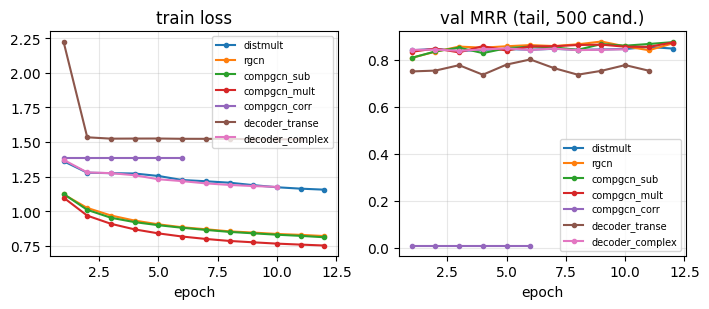

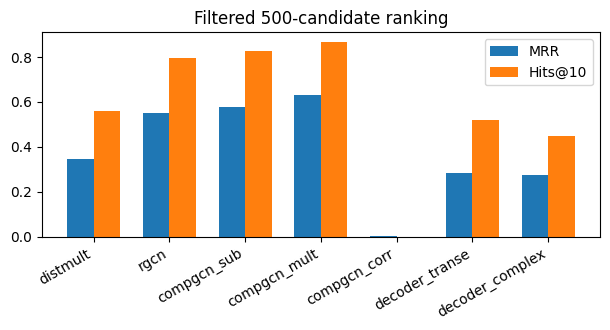

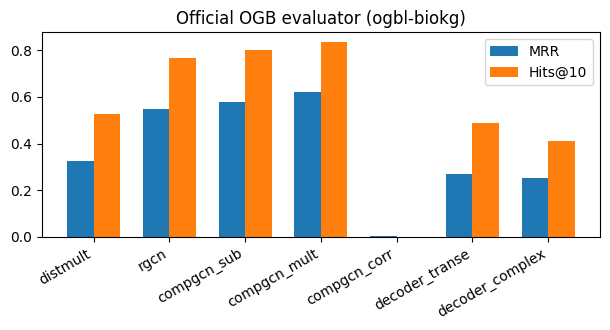

In [32]:
plt.figure(figsize=(7.2, 3.2))
ax1 = plt.subplot(1, 2, 1); ax2 = plt.subplot(1, 2, 2)
for name, h in histories.items():
    ax1.plot(range(1, len(h['loss']) + 1), h['loss'], marker='.', label=name)
    ax2.plot(range(1, len(h['val_mrr']) + 1), h['val_mrr'], marker='.', label=name)
ax1.set_title('train loss'); ax1.set_xlabel('epoch'); ax1.legend(fontsize=7); ax1.grid(True, alpha=0.3)
ax2.set_title('val MRR (tail, 500 cand.)'); ax2.set_xlabel('epoch'); ax2.legend(fontsize=7); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / 'fig_train_curves.png', dpi=160); plt.show()

scored = {k: v for k, v in results.items() if 'MRR' in v}
if scored:
    dfm = pd.DataFrame(scored).T.reset_index().rename(columns={'index': 'model'})
    plt.figure(figsize=(6.2, 3.4))
    x = np.arange(len(dfm)); w = 0.35
    plt.bar(x - w/2, dfm['MRR'].astype(float), width=w, label='MRR')
    plt.bar(x + w/2, dfm['Hits@10'].astype(float), width=w, label='Hits@10')
    plt.xticks(x, dfm['model'], rotation=30, ha='right'); plt.title('Filtered 500-candidate ranking')
    plt.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig_main_bars.png', dpi=160); plt.show()
    dfm.drop(columns=['ogb'], errors='ignore').to_csv(OUT / 'main_results.csv', index=False)

ogb_rows = {k: v['ogb'] for k, v in results.items() if 'ogb' in v}
if ogb_rows:
    dfo = pd.DataFrame(ogb_rows).T
    dfo.to_csv(OUT / 'ogb_results.csv')
    plt.figure(figsize=(6.2, 3.4))
    x = np.arange(len(dfo)); w = 0.35
    plt.bar(x - w/2, dfo['mrr_list'], width=w, label='MRR')
    plt.bar(x + w/2, dfo['hits@10_list'], width=w, label='Hits@10')
    plt.xticks(x, dfo.index, rotation=30, ha='right'); plt.title('Official OGB evaluator (ogbl-biokg)')
    plt.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig_ogb_bars.png', dpi=160); plt.show()


### 8.2 Error analysis

MRR by Bordes relation category (often a single N–N bar on biokg) and by head-entity **degree quartile**.
Rare entities are the hard cases.


error-analysis {'MRR': 0.6302, 'MR': 9.4555, 'Hits@1': 0.502, 'Hits@3': 0.7152, 'Hits@10': 0.8674, 'MRR_tail': 0.6716, 'MRR_head': 0.5887, 'n_eval': 15000, 'n_candidates': 500, 'protocol': 'filtered-candidates head+tail'}
MRR by relation category
 cat
1-1         NaN
1-N         NaN
N-1         NaN
N-N    0.504109
Name: recip, dtype: float64


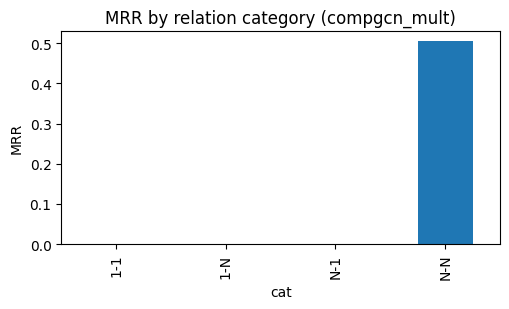

MRR by degree bin
 deg_bin
(0.999, 136.0]       0.401151
(136.0, 741.0]       0.499274
(741.0, 5551.0]      0.567941
(5551.0, 62733.0]    0.548623
Name: recip, dtype: float64


/tmp/ipykernel_49/4077230637.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_deg = edf.groupby('deg_bin')['recip'].mean()


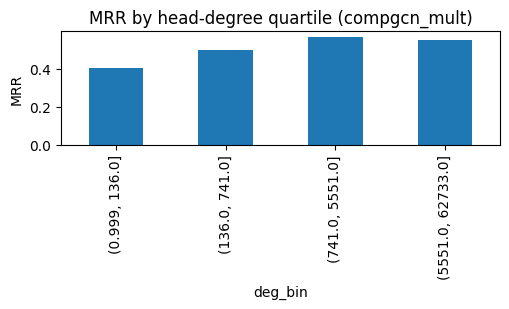

In [33]:
error_analysis = {}
scored = {k: v for k, v in results.items() if 'MRR' in v}
if not scored:
    print('no results')
else:
    best_name = max(scored, key=lambda k: scored[k]['MRR'])
    model = models_keep.get(best_name)
    if model is None:
        ck = OUT / f'{best_name}.pt'
        builder = BUILDERS.get(best_name)
        if builder is None and best_name.startswith('decoder_'):
            builder = EXTRA_BUILD.get(best_name.replace('decoder_', ''))
        if builder is not None and ck.exists():
            model = builder()
            model.load_state_dict(torch.load(ck, map_location='cpu'))
        else:
            print('skip error analysis: no model', best_name)
    if model is None:
        print('skip error analysis')
    else:
        model = model.to(DEVICE)
        use_gnn = hasattr(model, 'encode')
        eval_triples = test_np[:MAX_EVAL_TRIPLES] if MAX_EVAL_TRIPLES else test_np[:5000]
        _, ranks = eval_full(model, eval_triples, use_gnn, FANOUT, tag='error-analysis')
        deg_arr = np.bincount(np.concatenate([train_np[:, 0], train_np[:, 2]]), minlength=N_ENT)
        recs = []
        for i, tr in enumerate(eval_triples[:len(ranks)]):
            recs.append({'rank': float(ranks[i]), 'rel': int(tr[1]),
                         'cat': relcat_map.get(int(tr[1]), 'UNK'), 'deg': int(deg_arr[int(tr[0])])})
        edf = pd.DataFrame(recs); edf['recip'] = 1.0 / edf['rank']
        by_cat = edf.groupby('cat')['recip'].mean().reindex(['1-1', '1-N', 'N-1', 'N-N'])
        print('MRR by relation category\n', by_cat)
        plt.figure(figsize=(5.2, 3.2)); by_cat.plot(kind='bar')
        plt.ylabel('MRR'); plt.title(f'MRR by relation category ({best_name})')
        plt.tight_layout(); plt.savefig(FIG / 'fig_mrr_by_relcat.png', dpi=160); plt.show()
        edf['deg_bin'] = pd.qcut(edf['deg'].clip(lower=1), q=min(4, edf['deg'].nunique()), duplicates='drop')
        by_deg = edf.groupby('deg_bin')['recip'].mean()
        print('MRR by degree bin\n', by_deg)
        plt.figure(figsize=(5.2, 3.2)); by_deg.plot(kind='bar')
        plt.ylabel('MRR'); plt.title(f'MRR by head-degree quartile ({best_name})')
        plt.tight_layout(); plt.savefig(FIG / 'fig_mrr_by_degree.png', dpi=160); plt.show()
        error_analysis = {
            'best_model': best_name,
            'mrr_by_relcat': {str(k): (None if pd.isna(v) else float(v)) for k, v in by_cat.items()},
            'mrr_by_degree': {str(k): float(v) for k, v in by_deg.items()},
        }
        del model; torch.cuda.empty_cache(); gc.collect()


### 8.3 Embedding projection

UMAP of a subsample of entity embeddings (t-SNE fallback if `umap-learn` is missing).


I0000 00:00:1793968838.743174      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


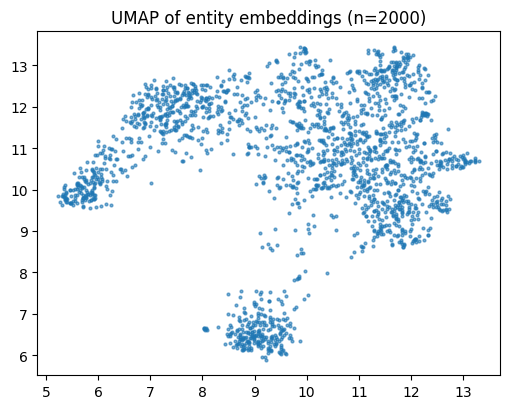

In [34]:
if RUN_UMAP:
    from sklearn.manifold import TSNE
    m = models_keep.get('compgcn_mult') or models_keep.get('rgcn')
    if m is None:
        for _n in ('compgcn_mult', 'rgcn', 'distmult'):
            ck = OUT / f'{_n}.pt'
            if _n in BUILDERS and ck.exists():
                m = BUILDERS[_n](); m.load_state_dict(torch.load(ck, map_location='cpu')); break
    if m is None:
        print('UMAP skipped: no model')
    else:
        with torch.no_grad():
            z = m.ent.weight.detach().cpu().numpy()
        n_plot = min(2000, z.shape[0])
        idx = np.random.default_rng(SEED).choice(z.shape[0], size=n_plot, replace=False)
        try:
            import umap
            y = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(z[idx]); method = 'UMAP'
        except Exception as e:
            print('UMAP failed, t-SNE fallback', e)
            y = TSNE(n_components=2, init='pca', random_state=SEED, perplexity=30).fit_transform(z[idx]); method = 't-SNE'
        plt.figure(figsize=(5.2, 4.2)); plt.scatter(y[:, 0], y[:, 1], s=4, alpha=0.6)
        plt.title(f'{method} of entity embeddings (n={n_plot})')
        plt.tight_layout(); plt.savefig(FIG / 'fig_umap_entities.png', dpi=160); plt.show()
        del m; gc.collect()
else:
    print('skip UMAP')


---
## 9 · Export results

Writes `outputs/results.json` (full payload: metrics, OGB, ablations, Spark scale, training flags)
plus CSV summaries used by the LaTeX report.


In [35]:
payload = {
    'DATASET': DATASET, 'MACHINE': MACHINE, 'QUICK_RUN': QUICK_RUN, 'TIME_BUDGET': TIME_BUDGET,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'vram_gb': torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0,
    'preset': P, 'spark_stats': spark_stats, 'spark_scale': scale_rows,
    'main_results': results, 'ablation': ablation, 'error_analysis': error_analysis,
    'n_ent': N_ENT, 'n_rel': N_REL, 'n_train': int(len(train_np)),
    'budget': {'distmult': {'epochs': EPOCHS_DM, 'steps': STEPS_DM, 'neg': NUM_NEG_DM},
               'gnn': {'epochs': EPOCHS_GNN, 'steps': STEPS_GNN, 'neg': NUM_NEG},
               'batch': BATCH_SIZE, 'fanout': FANOUT, 'dim': EMBED_DIM, 'layers': NUM_LAYERS, 'bases': NUM_BASES},
    'eval': {'n_candidates': N_CANDIDATES, 'max_eval_triples': MAX_EVAL_TRIPLES, 'seed': SEED,
             'ogb_test_triples': 0 if OGB_TEST is None else int(len(OGB_TEST['pos']))},
    'training': {
        'bidirectional': True, 'residual_query': True,
        'matched_distmult': MATCHED_DISTMULT, 'adv_neg': ADV_NEG, 'adv_temp': ADV_TEMP,
        'type_aware_neg': bool(TYPE_AWARE_NEG and TYPE_POOLS is not None),
        'extra_decoders': EXTRA_DECODERS,
    },
    'wall_clock_h': round(elapsed_h(), 3),
    'figures': sorted([p.name for p in FIG.glob('*.png')]),
}
with open(OUT / 'results.json', 'w', encoding='utf-8') as f:
    json.dump(payload, f, indent=2, default=str)
print('wrote', OUT / 'results.json')
print('\n===== COPY INTO THE REPORT (do not invent extra digits) =====')
print(json.dumps({k: payload[k] for k in ['DATASET', 'MACHINE', 'gpu', 'main_results', 'spark_stats']}, indent=2, default=str))
print('Figures:', payload['figures'])
failed = {k: v['error'] for k, v in results.items() if 'error' in v}
print('ALL MODELS OK' if not failed else f'FAILED / SKIPPED: {failed}')
mem_report('end')


wrote /kaggle/working/outputs/results.json

===== COPY INTO THE REPORT (do not invent extra digits) =====
{
  "DATASET": "biokg",
  "MACHINE": "kaggle_t4",
  "gpu": "Tesla T4",
  "main_results": {
    "distmult": {
      "MRR": 0.34836795926094055,
      "MR": 63.39303207397461,
      "Hits@1": 0.24316667020320892,
      "Hits@3": 0.3912000060081482,
      "Hits@10": 0.5616999864578247,
      "MRR_tail": 0.3624843657016754,
      "MRR_head": 0.3342515528202057,
      "n_eval": 15000,
      "n_candidates": 500,
      "protocol": "filtered-candidates head+tail",
      "train_hours": 0.026,
      "ogb": {
        "hits@1_list": 0.22440597414970398,
        "hits@3_list": 0.3635998070240021,
        "hits@10_list": 0.5264075398445129,
        "mrr_list": 0.3251885175704956
      }
    },
    "rgcn": {
      "MRR": 0.549014151096344,
      "MR": 13.471866607666016,
      "Hits@1": 0.42053332924842834,
      "Hits@3": 0.6236000061035156,
      "Hits@10": 0.7978000044822693,
      "MRR_tail":

### 9.1 Download zip

Packs `outputs/` + `figures/` for the report / slide pipeline.
On Kaggle this cell shows a download link.


In [36]:
import zipfile
from IPython.display import FileLink, display

zip_path = ROOT / 'kgc_report_artifacts.zip'
skip_dir_names = {'ogb', 'parquet', 'spark-tmp', 'spark-warehouse', '__pycache__', 'fb15k237'}

def keep(p: Path) -> bool:
    if any(part in skip_dir_names for part in p.parts):
        return False
    return p.suffix.lower() in {'.png', '.csv', '.json', '.txt', '.md'}

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in (FIG, OUT):
        if not folder.exists():
            print('missing', folder); continue
        for p in folder.rglob('*'):
            if p.is_file() and keep(p):
                z.write(p, p.relative_to(ROOT))
                print('added', p.relative_to(ROOT))

print('wrote', zip_path, 'size_mb', round(zip_path.stat().st_size / 1e6, 2))
if IS_KAGGLE:
    display(FileLink(str(zip_path.relative_to(ROOT))))


added figures/fig_mrr_by_degree.png
added figures/fig_train_curves.png
added figures/fig_degree_loglog.png
added figures/fig_ogb_bars.png
added figures/fig_spark_scale.png
added figures/fig_mrr_by_relcat.png
added figures/fig_main_bars.png
added figures/fig_umap_entities.png
added outputs/ogb_results.csv
added outputs/results_partial.json
added outputs/main_results.csv
added outputs/results.json
added outputs/ablation.json
added outputs/spark_scale.csv
wrote /kaggle/working/kgc_report_artifacts.zip size_mb 0.41


/kaggle/working/kgc_report_artifacts.zip